In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [15]:

sales = pd.read_csv("/content/sales.csv")
products = pd.read_csv("/content/products.csv")
stores = pd.read_csv("/content/stores.csv")
promotions = pd.read_csv("/content/promotions.csv")
calendar = pd.read_csv("/content/calendar.csv")

print("All five datasets loaded successfully!")
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


All five datasets loaded successfully!
Sales: (78997, 6)
Products: (60, 4)
Stores: (12, 4)
Promotions: (5, 3)
Calendar: (365, 5)


In [16]:

for name, df in {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}.items():

    print("\n==========", name, "==========")

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())



========== Sales ==========

Missing Values:
date           0
store          0
product        0
units          0
revenue        0
campaign    1185
dtype: int64

Duplicate Rows:
157

========== Products ==========

Missing Values:
product       0
category      0
brand         0
price band    0
dtype: int64

Duplicate Rows:
0

========== Stores ==========

Missing Values:
store         0
city          0
format        0
floor area    0
dtype: int64

Duplicate Rows:
0

========== Promotions ==========

Missing Values:
campaign    0
discount    0
duration    0
dtype: int64

Duplicate Rows:
0

========== Calendar ==========

Missing Values:
date        0
weekday     0
holiday     0
festival    0
season      0
dtype: int64

Duplicate Rows:
0


In [17]:

print("Zero units:", (sales["units"] == 0).sum())
print("Negative units:", (sales["units"] < 0).sum())
print("Negative revenue:", (sales["revenue"] < 0).sum())

display(sales.describe())


Zero units: 118
Negative units: 118
Negative revenue: 118


,units,revenue
count,78997.000000,78997.000000
mean,7.004481,3610.003576
std,4.182211,3259.622152
min,-1.000000,-17334.000000
25%,4.000000,1134.000000
50%,6.000000,2584.000000
75%,10.000000,5145.000000
max,34.000000,25952.200000


In [18]:

# Remove duplicate records from each dataset
sales = sales.drop_duplicates().copy()
products = products.drop_duplicates().copy()
stores = stores.drop_duplicates().copy()
promotions = promotions.drop_duplicates().copy()
calendar = calendar.drop_duplicates().copy()

print("Duplicate rows removed successfully!")

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


Duplicate rows removed successfully!
Sales: (78840, 6)
Products: (60, 4)
Stores: (12, 4)
Promotions: (5, 3)
Calendar: (365, 5)


In [19]:

# Remove extra spaces and standardize category names
products["category"] = (
    products["category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Display category counts
print(products["category"].value_counts(dropna=False))



category
personal care    20
dairy            12
beverages         9
grocery           8
household         6
snacks            5
Name: count, dtype: Int64


In [20]:

# Identify invalid sales records
invalid_mask = (
    sales["units"].isna()
    | sales["revenue"].isna()
    | (sales["units"] <= 0)
    | (sales["revenue"] < 0)
)

invalid_sales = sales[invalid_mask].copy()

# Keep a copy of invalid records for evidence
invalid_sales.to_csv(
    "/content/invalid_sales_audit.csv",
    index=False
)

print("Invalid records identified:", len(invalid_sales))

# Retain valid positive-sales records for analysis
sales = sales[~invalid_mask].copy()

print("Remaining sales records:", len(sales))
print("Invalid records saved for audit.")



Invalid records identified: 236
Remaining sales records: 78604
Invalid records saved for audit.


In [21]:

for name, df in {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}.items():
    print("\n", name)
    print(df.isnull().sum())



 Sales
date           0
store          0
product        0
units          0
revenue        0
campaign    1180
dtype: int64

 Products
product       0
category      0
brand         0
price band    0
dtype: int64

 Stores
store         0
city          0
format        0
floor area    0
dtype: int64

 Promotions
campaign    0
discount    0
duration    0
dtype: int64

 Calendar
date        0
weekday     0
holiday     0
festival    0
season      0
dtype: int64


In [22]:

# Convert date columns to datetime
sales["date"] = pd.to_datetime(sales["date"], errors="coerce")
calendar["date"] = pd.to_datetime(calendar["date"], errors="coerce")

# Merge sales with product details
df = sales.merge(
    products,
    on="product",
    how="left",
    validate="many_to_one"
)

# Merge store details
df = df.merge(
    stores,
    on="store",
    how="left",
    validate="many_to_one"
)

# Merge calendar details
df = df.merge(
    calendar,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Datasets merged successfully!")
print("Combined dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())


Datasets merged successfully!
Combined dataset shape: (78604, 16)


,date,store,product,units,revenue,campaign,category,brand,price band,city,format,floor area,weekday,holiday,festival,season
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter



Columns:
['date', 'store', 'product', 'units', 'revenue', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'floor area', 'weekday', 'holiday', 'festival', 'season']


In [23]:

df = df.merge(
    promotions,
    on="campaign",
    how="left",
    validate="many_to_one",
    suffixes=("", "_promotion")
)

print("Promotion data merged!")
print("Final dataset shape:", df.shape)
display(df.head())


Promotion data merged!
Final dataset shape: (78604, 18)


,date,store,product,units,revenue,campaign,category,brand,price band,city,format,floor area,weekday,holiday,festival,season,discount,duration
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,Express,4404,Wednesday,1,Festival Period,Winter,15.0,7.0


In [24]:

# Extract date-based features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["quarter"] = df["date"].dt.quarter
df["day_of_week"] = df["date"].dt.dayofweek
df["weekend"] = (df["day_of_week"] >= 5).astype(int)

print("New features created successfully!")
display(df.head())


New features created successfully!


,date,store,product,units,revenue,campaign,category,brand,price band,city,...,festival,season,discount,duration,year,month,month_name,quarter,day_of_week,weekend
0,2025-01-01,S001,P022,5,535.5,Festival Offer,dairy,HomeEase,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
1,2025-01-01,S001,P019,1,268.6,Festival Offer,household,FreshChoice,Budget,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
2,2025-01-01,S001,P047,4,1598.0,Festival Offer,household,SunPeak,Budget,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
3,2025-01-01,S001,P051,8,1482.4,Festival Offer,snacks,HomeEase,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0
4,2025-01-01,S001,P034,2,212.5,Festival Offer,dairy,DailyFarm,Mid-range,Coimbatore,...,Festival Period,Winter,15.0,7.0,2025,1,January,1,2,0


In [25]:

df.to_csv("/content/freshcart_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [26]:

from google.colab import files
files.download("/content/freshcart_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Revenue by Product Category:


,category,revenue
0,personal care,85562408.15
1,dairy,51252491.45
2,beverages,48658510.55
3,grocery,36521149.70
4,snacks,34012890.40
5,household,28997618.80


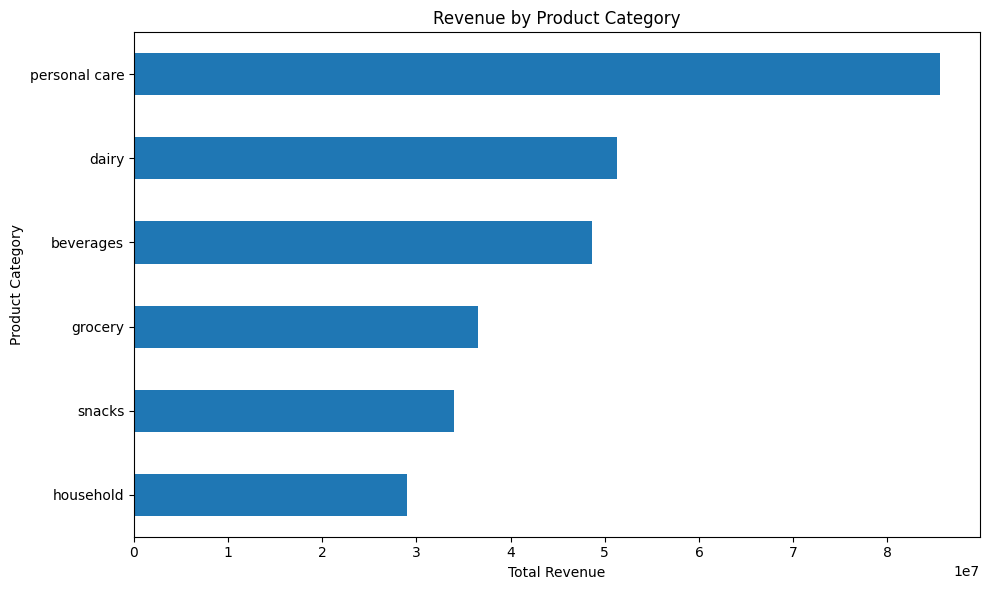

In [28]:

# Revenue by product category

category_revenue = (
    df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Category:")
display(category_revenue.reset_index())

# Create a bar chart
plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


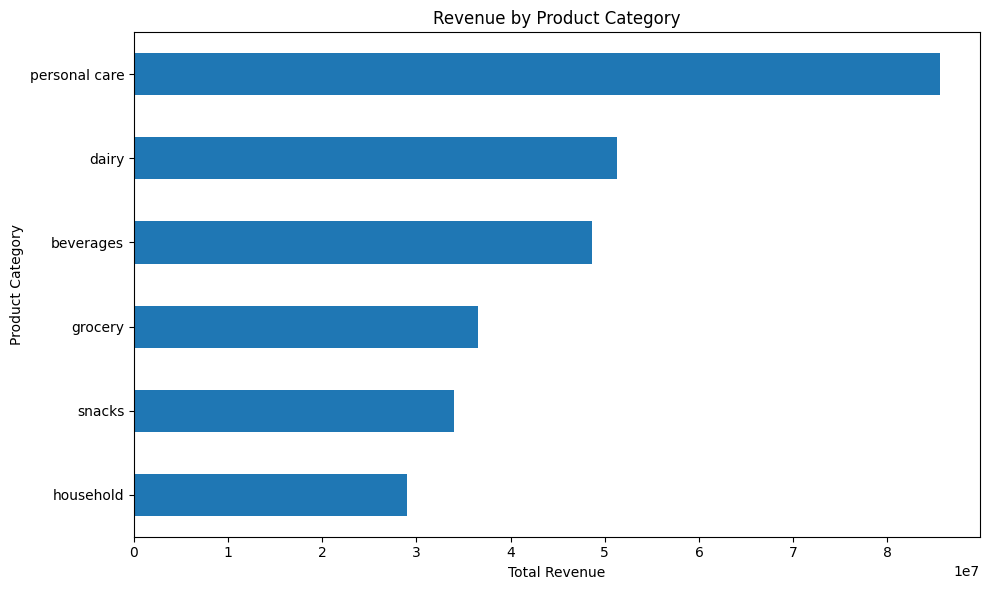

In [29]:

plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(kind="barh")

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig(
    "/content/category_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [32]:

# Calculate monthly revenue for each store
df["date"] = pd.to_datetime(df["date"])

monthly_store = (
    df.groupby([
        "store",
        pd.Grouper(key="date", freq="MS")
    ])["revenue"]
    .sum()
    .reset_index()
)

monthly_store.columns = [
    "store", "month", "monthly_revenue"
]

display(monthly_store.head(10))


,store,month,monthly_revenue
0,S001,2025-01-01,1556775.65
1,S001,2025-02-01,1292691.30
2,S001,2025-03-01,1463919.50
3,S001,2025-04-01,1446768.50
4,S001,2025-05-01,1457606.80
5,S001,2025-06-01,1339998.40
6,S001,2025-07-01,1466823.70
7,S001,2025-08-01,1533357.55
8,S001,2025-09-01,1383229.00
9,S001,2025-10-01,1437792.90


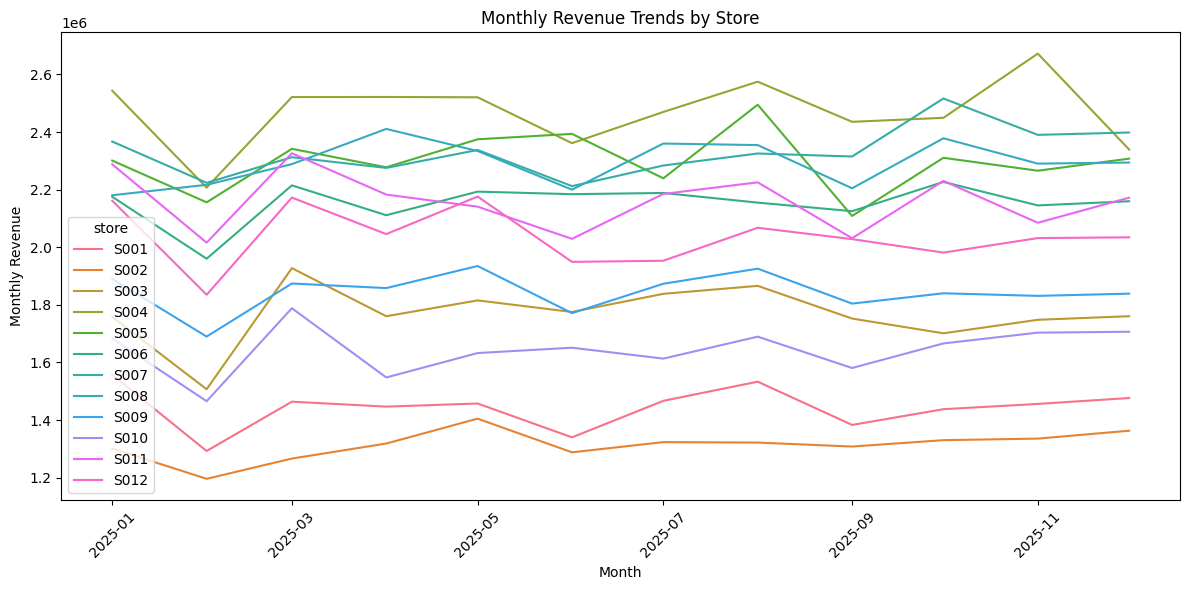

In [33]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_store,
    x="month",
    y="monthly_revenue",
    hue="store",
    estimator="sum",
    errorbar=None
)

plt.title("Monthly Revenue Trends by Store")
plt.xlabel("Month")
plt.ylabel("Monthly Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [34]:

store_growth = (
    monthly_store.sort_values("month")
    .groupby("store")
    .agg(
        first_revenue=("monthly_revenue", "first"),
        last_revenue=("monthly_revenue", "last")
    )
)

store_growth["growth_percent"] = np.where(
    store_growth["first_revenue"] > 0,
    (
        (store_growth["last_revenue"] -
         store_growth["first_revenue"])
        / store_growth["first_revenue"]
    ) * 100,
    np.nan
)

store_growth = store_growth.sort_values(
    "growth_percent", ascending=False
)

display(store_growth)


,first_revenue,last_revenue,growth_percent
store,,,
S008,2180707.15,2294243.7,5.206410
S002,1301286.40,1363081.0,4.748732
S010,1683261.35,1706730.8,1.394284
S007,2367191.80,2398524.1,1.323606
S005,2300957.10,2307846.5,0.299415
S003,1758051.35,1760703.3,0.150846
S006,2175451.70,2159822.0,-0.718458
S009,1890290.20,1838978.2,-2.714504
S011,2288017.15,2172247.6,-5.059820


In [35]:

# Analyze sales by promotion campaign

promotion_summary = (
    df.groupby("campaign", dropna=False)
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum"),
        average_revenue=("revenue", "mean"),
        sales_records=("revenue", "count")
    )
    .sort_values("total_revenue", ascending=False)
)

display(promotion_summary)


,total_revenue,total_units,average_revenue,sales_records
campaign,,,,
No Promotion,1.821452e+08,338190,3519.985448,51746
Weekend Deal,8.044264e+07,166496,3754.966321,21423
Festival Offer,1.797838e+07,39383,4225.235934,4255
NaN,4.438880e+06,8289,3761.762415,1180


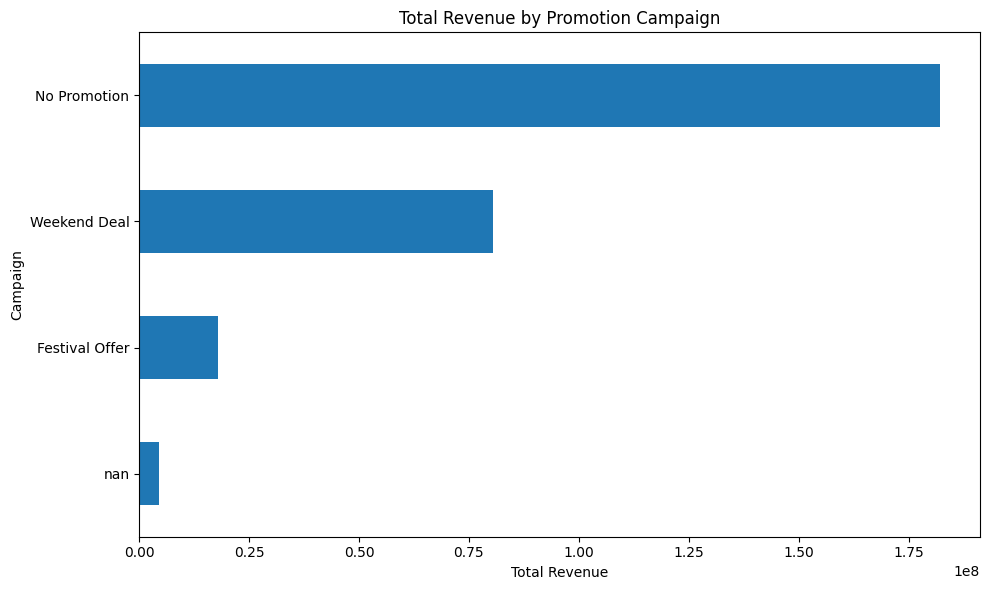

In [36]:

plt.figure(figsize=(10, 6))

promotion_summary["total_revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Total Revenue by Promotion Campaign")
plt.xlabel("Total Revenue")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()


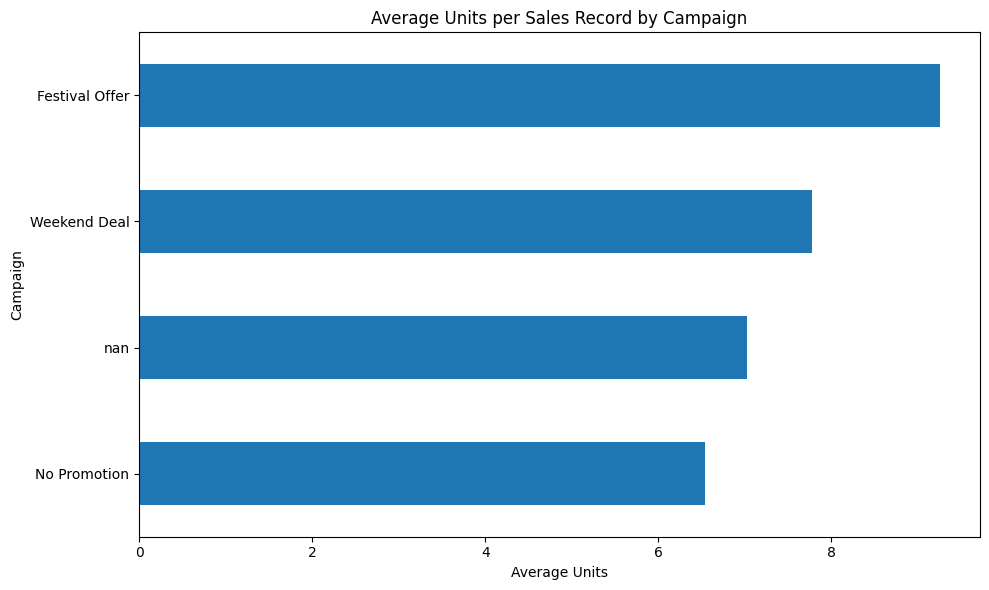

In [37]:

plt.figure(figsize=(10, 6))

promotion_summary["total_units"].div(
    promotion_summary["sales_records"].replace(0, np.nan)
).sort_values().plot(kind="barh")

plt.title("Average Units per Sales Record by Campaign")
plt.xlabel("Average Units")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()


In [38]:

# Compare sales during festival and non-festival periods

festival_summary = (
    df.groupby("festival", dropna=False)
    .agg(
        total_units=("units", "sum"),
        average_units=("units", "mean"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

display(festival_summary)


,festival,total_units,average_units,total_revenue
0,Festival Period,39858,9.254237,1.821702e+07
1,No Festival,512500,6.897990,2.667881e+08


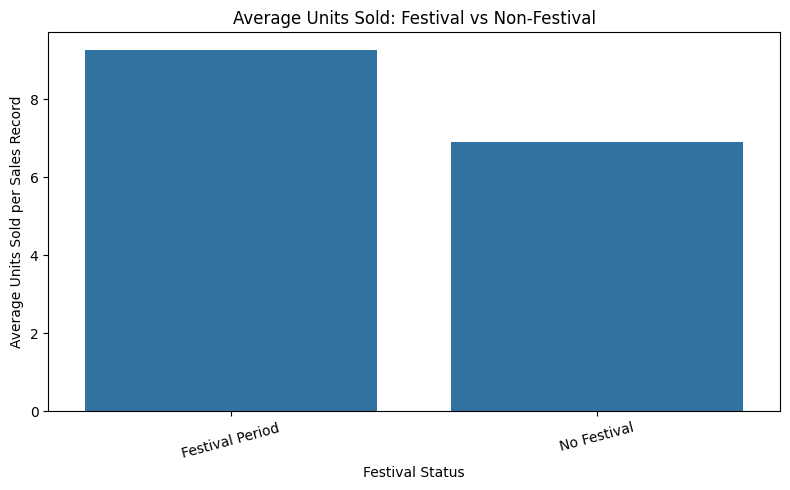

In [39]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=festival_summary,
    x="festival",
    y="average_units"
)

plt.title("Average Units Sold: Festival vs Non-Festival")
plt.xlabel("Festival Status")
plt.ylabel("Average Units Sold per Sales Record")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


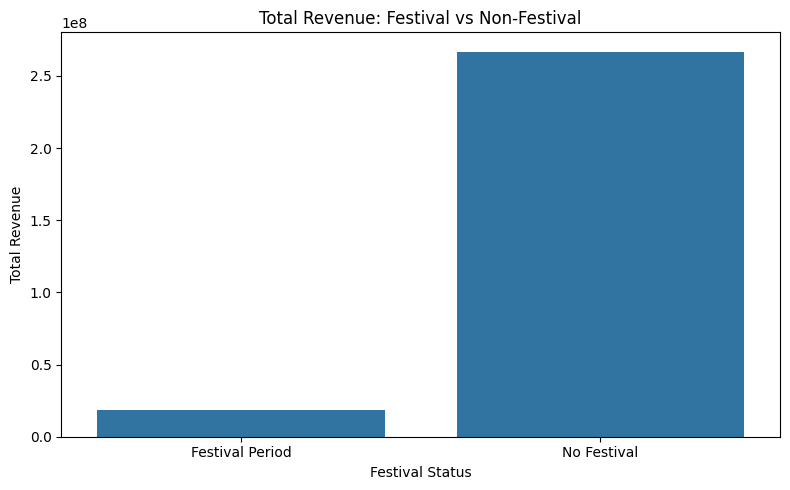

In [40]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=festival_summary,
    x="festival",
    y="total_revenue"
)

plt.title("Total Revenue: Festival vs Non-Festival")
plt.xlabel("Festival Status")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


In [41]:

# Product demand by season

seasonal_sales = (
    df.groupby(["product", "season"])
    .agg(
        total_units=("units", "sum"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

display(seasonal_sales.head(15))


,product,season,total_units,total_revenue
0,P001,Monsoon,2454,1299616.15
1,P001,Post-Monsoon,1501,784541.35
2,P001,Summer,2110,1113130.20
3,P001,Winter,1704,905623.60
4,P002,Monsoon,1512,705212.20
5,P002,Post-Monsoon,825,377810.40
6,P002,Summer,1081,503384.20
7,P002,Winter,1264,587382.40
8,P003,Monsoon,3771,2944294.95
9,P003,Post-Monsoon,2157,1652655.80


In [42]:

# Find the season with the highest units sold for each product

product_season = (
    seasonal_sales.sort_values("total_units", ascending=False)
    .drop_duplicates(subset="product")
    .sort_values("total_units", ascending=False)
)

print("Top 15 product-season combinations:")
display(product_season.head(15))


Top 15 product-season combinations:


,product,season,total_units,total_revenue
184,P047,Monsoon,4990,2261922.00
60,P016,Monsoon,4868,4200035.80
128,P033,Monsoon,4837,1551246.30
44,P012,Monsoon,4795,189823.85
156,P040,Monsoon,4763,255304.00
192,P049,Monsoon,4591,4264404.75
148,P038,Monsoon,4532,1068445.00
216,P055,Monsoon,4516,2732281.65
236,P060,Monsoon,4485,4035799.55
16,P005,Monsoon,4484,4108353.30


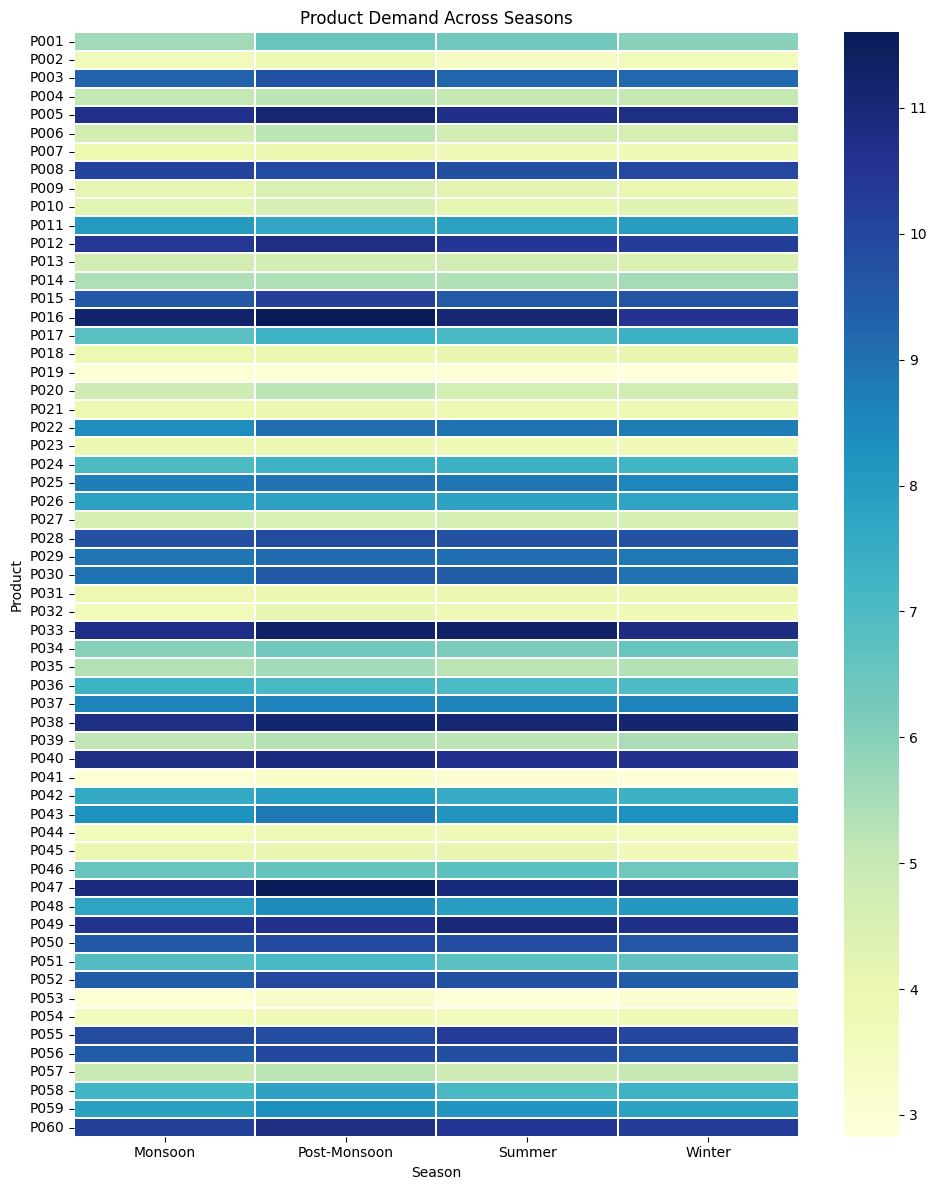

In [43]:

# Average units sold per product in each season

season_pivot = df.pivot_table(
    index="product",
    columns="season",
    values="units",
    aggfunc="mean"
)

plt.figure(figsize=(10, 12))

sns.heatmap(
    season_pivot,
    cmap="YlGnBu",
    linewidths=0.2
)

plt.title("Product Demand Across Seasons")
plt.xlabel("Season")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


,total_revenue,total_units
weekday_name,,
Monday,39344941.35,74744
Tuesday,40177918.05,75472
Wednesday,40470856.85,76375
Thursday,39971660.85,74416
Friday,40055269.95,75088
Saturday,42355014.10,88180
Sunday,42629407.90,88083


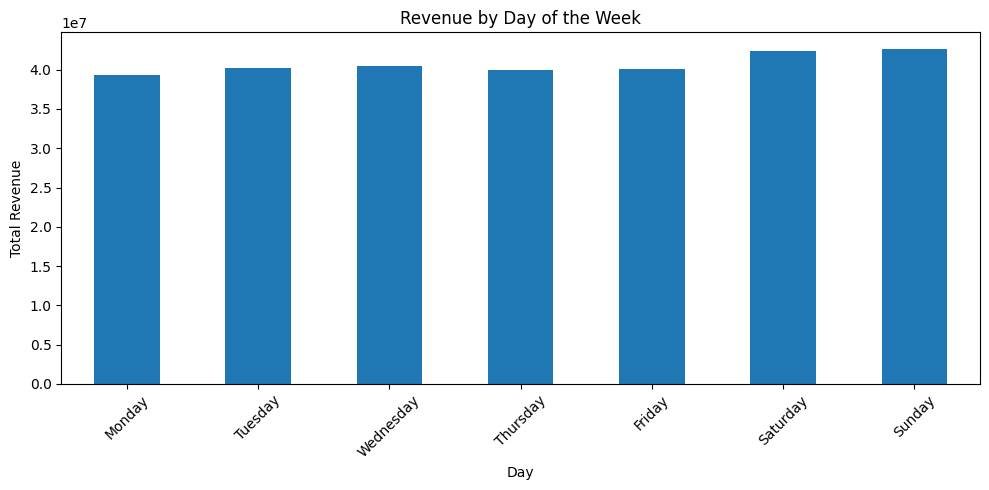

In [47]:

# Create weekday_name from the date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["weekday_name"] = df["date"].dt.day_name()

# Total revenue and units by weekday
weekday_sales = (
    df.groupby("weekday_name")
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

display(weekday_sales)

# Plot revenue by weekday
weekday_sales["total_revenue"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,total_revenue,total_units
weekday_name,,
Monday,39344941.35,74744
Tuesday,40177918.05,75472
Wednesday,40470856.85,76375
Thursday,39971660.85,74416
Friday,40055269.95,75088
Saturday,42355014.10,88180
Sunday,42629407.90,88083


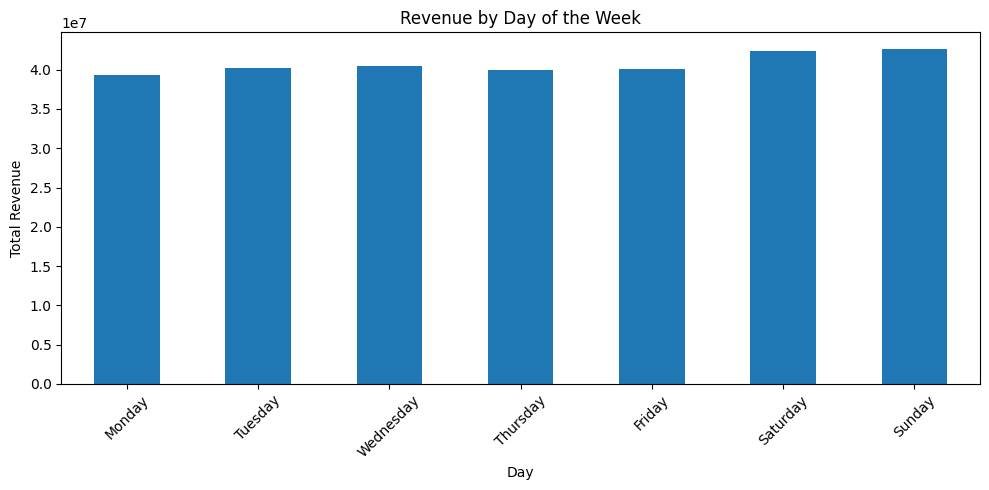

In [50]:
# Total revenue by day of the week

weekday_sales = (
    df.groupby("weekday_name")
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(weekday_order)

display(weekday_sales)

weekday_sales["total_revenue"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:

# Convert date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Create month features if they don't exist
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

# Calculate monthly sales
monthly_sales = (
    df.groupby(["month", "month_name"])
    .agg(
        total_revenue=("revenue", "sum"),
        total_units=("units", "sum")
    )
    .reset_index()
    .sort_values("month")
)

display(monthly_sales)


,month,month_name,total_revenue,total_units
0,1,January,24207506.95,47764
1,2,February,21767036.00,41322
2,3,March,24499542.40,46750
3,4,April,23758722.90,46855
4,5,May,24324441.10,46462
5,6,June,23156799.20,44302
6,7,July,23796263.60,45888
7,8,August,24535856.15,48486
8,9,September,23079056.90,44104
9,10,October,24070331.00,47316


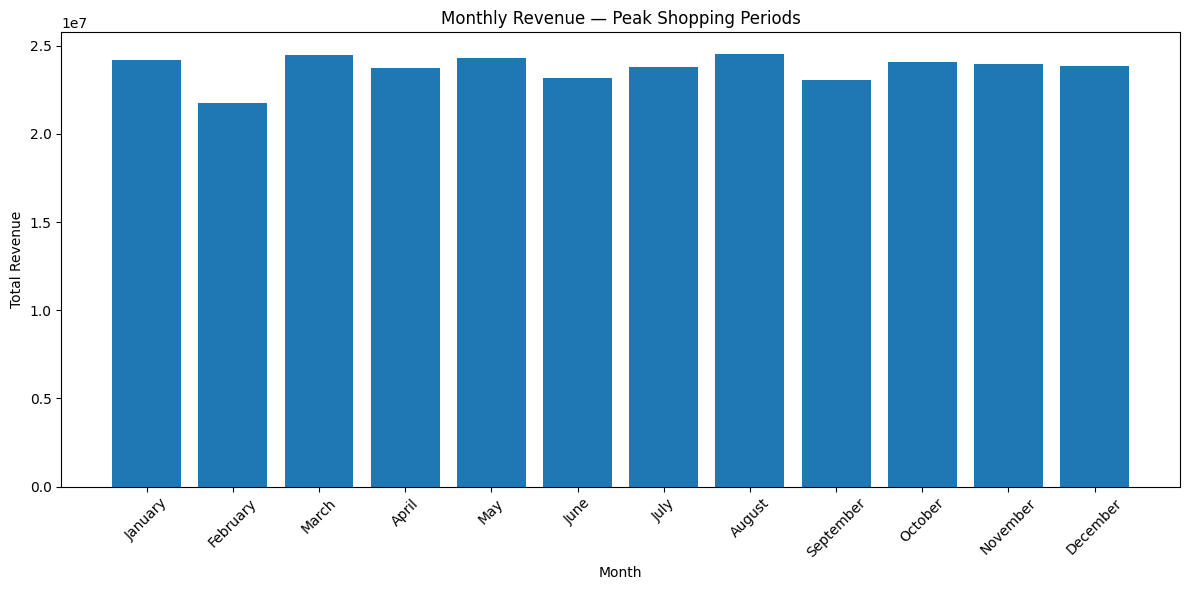

In [52]:

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_sales["month_name"],
    monthly_sales["total_revenue"]
)

plt.title("Monthly Revenue — Peak Shopping Periods")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [53]:

peak_month = monthly_sales.loc[
    monthly_sales["total_revenue"].idxmax()
]

print("Peak Revenue Month:", peak_month["month_name"])
print("Total Revenue:", round(peak_month["total_revenue"], 2))

peak_units_month = monthly_sales.loc[
    monthly_sales["total_units"].idxmax()
]

print("Peak Units Month:", peak_units_month["month_name"])
print("Total Units:", int(peak_units_month["total_units"]))


Peak Revenue Month: August
Total Revenue: 24535856.15
Peak Units Month: August
Total Units: 48486


In [61]:

from sklearn.preprocessing import LabelEncoder

# Create a separate dataset for feature engineering
feature_df = df.copy()

# Select categorical columns
categorical_cols = feature_df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Encode categorical variables
label_encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()

    feature_df[col] = encoder.fit_transform(
        feature_df[col].fillna("Unknown").astype(str)
    )

    label_encoders[col] = encoder

print("\nCategorical encoding completed! Ready for model training.")
display(feature_df.head())


Categorical columns: ['store', 'product', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'weekday', 'festival', 'season', 'month_name', 'weekday_name']

Categorical encoding completed! Ready for model training.


,date,store,product,units,revenue,campaign,category,brand,price band,city,...,season,discount,duration,year,month,month_name,quarter,day_of_week,weekend,weekday_name
0,2025-01-01,0,21,5,535.5,0,1,2,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
1,2025-01-01,0,18,1,268.6,0,3,1,0,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
2,2025-01-01,0,46,4,1598.0,0,3,4,0,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
3,2025-01-01,0,50,8,1482.4,0,5,2,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6
4,2025-01-01,0,33,2,212.5,0,1,0,1,1,...,3,15.0,7.0,2025,1,4,1,2,0,6


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define target and features
# We exclude 'date', 'units' (target), 'revenue' (which is highly correlated/leaks target info)
exclude_cols = ['date', 'units', 'revenue']
features = [col for col in feature_df.columns if col not in exclude_cols]

X = feature_df[features]
y = feature_df['units']

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (62883, 22)
Testing set shape: (15721, 22)


In [63]:
# Initialize and train the Random Forest Regressor
print("Training the model (this might take a few moments)... ")
model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Results:")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

Training the model (this might take a few moments)... 

Model Evaluation Results:
Root Mean Squared Error (RMSE): 2.8949
R2 Score: 0.5248


/tmp/ipykernel_2928/2379509672.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis')


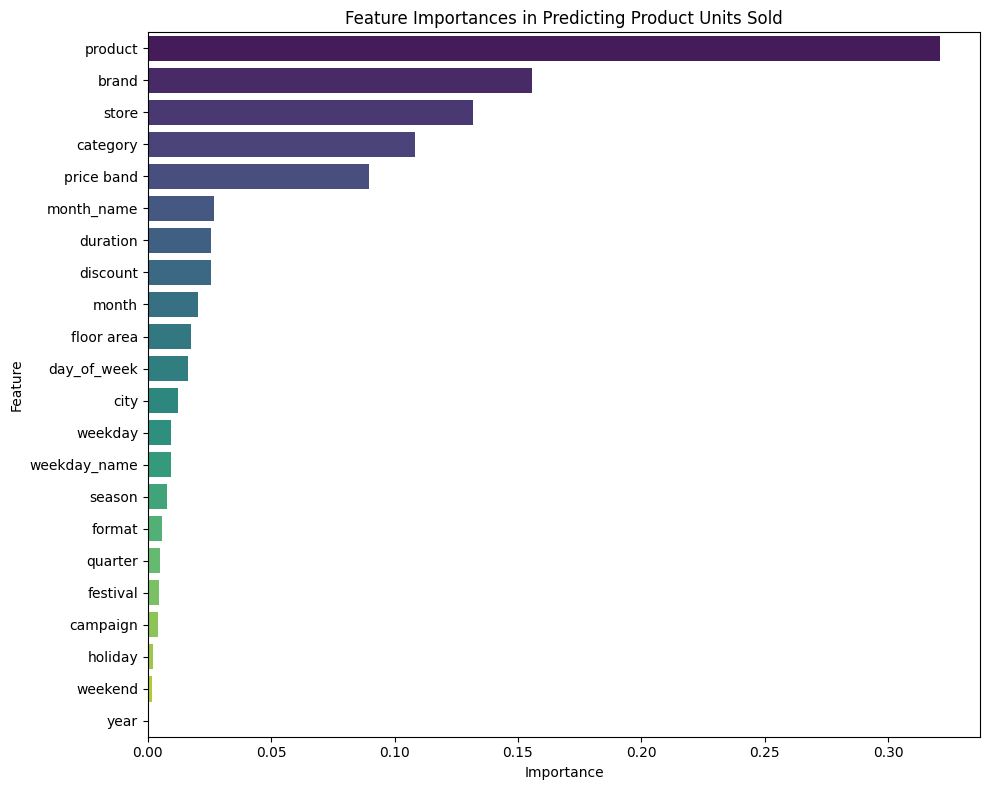

In [64]:
# Calculate and plot feature importance
importances = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importances in Predicting Product Units Sold')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [65]:
import os

# Create output folder
os.makedirs("/content/freshcart_outputs", exist_ok=True)

# Save cleaned dataset
df.to_csv(
    "/content/freshcart_outputs/freshcart_cleaned.csv",
    index=False
)

# Save analysis tables
category_revenue.to_csv(
    "/content/freshcart_outputs/category_revenue.csv"
)

monthly_sales.to_csv(
    "/content/freshcart_outputs/monthly_sales.csv",
    index=False
)

weekday_sales.to_csv(
    "/content/freshcart_outputs/weekday_sales.csv"
)

print("All existing analysis files saved successfully!")

All existing analysis files saved successfully!


In [57]:

import shutil

shutil.make_archive(
    "/content/FreshCart_Round2_Results",
    "zip",
    "/content/freshcart_outputs"
)

print("ZIP file created successfully!")


ZIP file created successfully!


In [58]:

from google.colab import files

files.download("/content/FreshCart_Round2_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ROUND 3

In [60]:
from google.colab import files
files.download("/content/freshcart_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Reasoning**:
We start the exploratory analysis and feature engineering visualization subtask by loading the cleaned dataset, running descriptive statistics on the target 'units', and computing/plotting the correlation heatmap to address multicollinearity as instructed.



Loaded cleaned dataset with shape: (78604, 24)

--- Descriptive Statistics for 'units' ---
count    78604.000000
mean         7.027098
std          4.167211
min          1.000000
25%          4.000000
50%          6.000000
75%         10.000000
max         34.000000
Name: units, dtype: float64


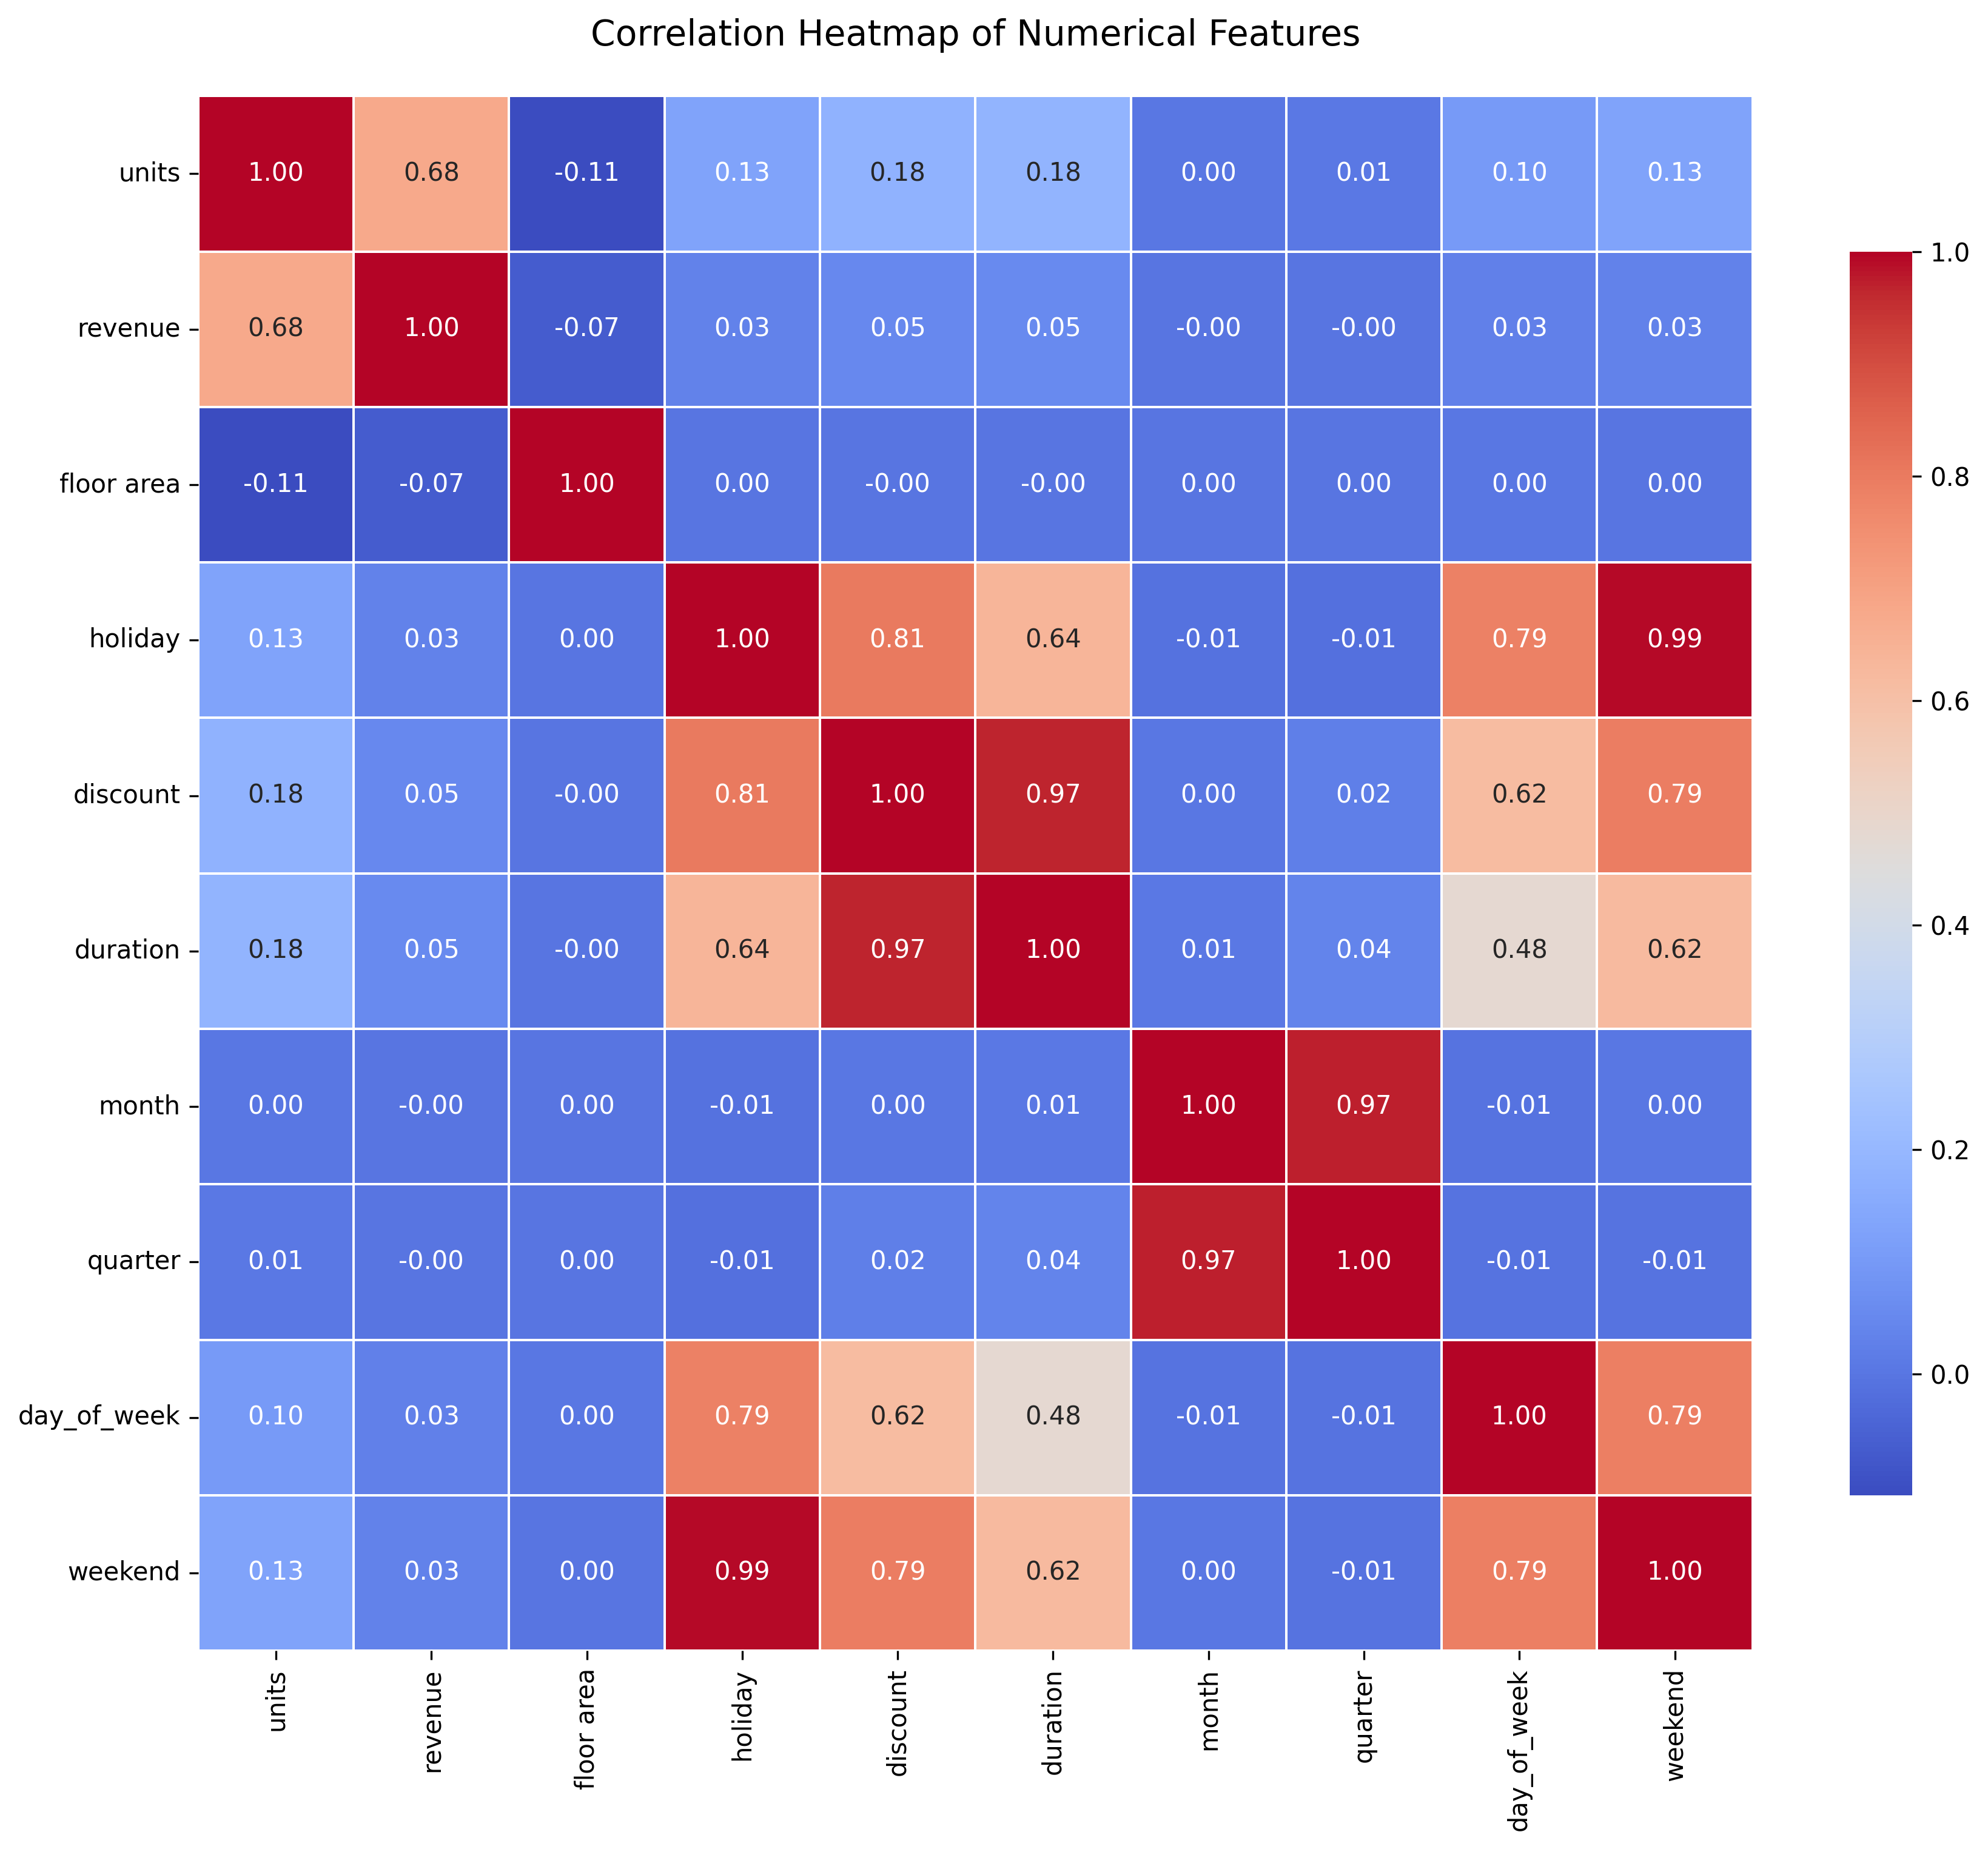

Correlation heatmap successfully saved to /content/freshcart_outputs/correlation_heatmap.png


In [66]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the cleaned dataset
data_path = "/content/freshcart_cleaned.csv"
df_clean = pd.read_csv(data_path)
print("Loaded cleaned dataset with shape:", df_clean.shape)

# 2. Descriptive statistics for target variable 'units'
print("\n--- Descriptive Statistics for 'units' ---")
print(df_clean['units'].describe())

# 3. Compute correlation matrix for numerical features
# Select numerical features
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
# Exclude year if it is constant/has no variance
if 'year' in num_cols and df_clean['year'].nunique() <= 1:
    num_cols.remove('year')

corr_matrix = df_clean[num_cols].corr()

# Plot a high-resolution heatmap
plt.figure(figsize=(12, 10), dpi=300)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, pad=20)
plt.tight_layout()

# 4. Save the correlation heatmap
os.makedirs("/content/freshcart_outputs", exist_ok=True)
heatmap_path = "/content/freshcart_outputs/correlation_heatmap.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Correlation heatmap successfully saved to {heatmap_path}")

**Reasoning**:
Generate exploratory visualizations including a boxplot of units sold by price band and a bar plot of average units sold by discount status to identify promotional and pricing trends.



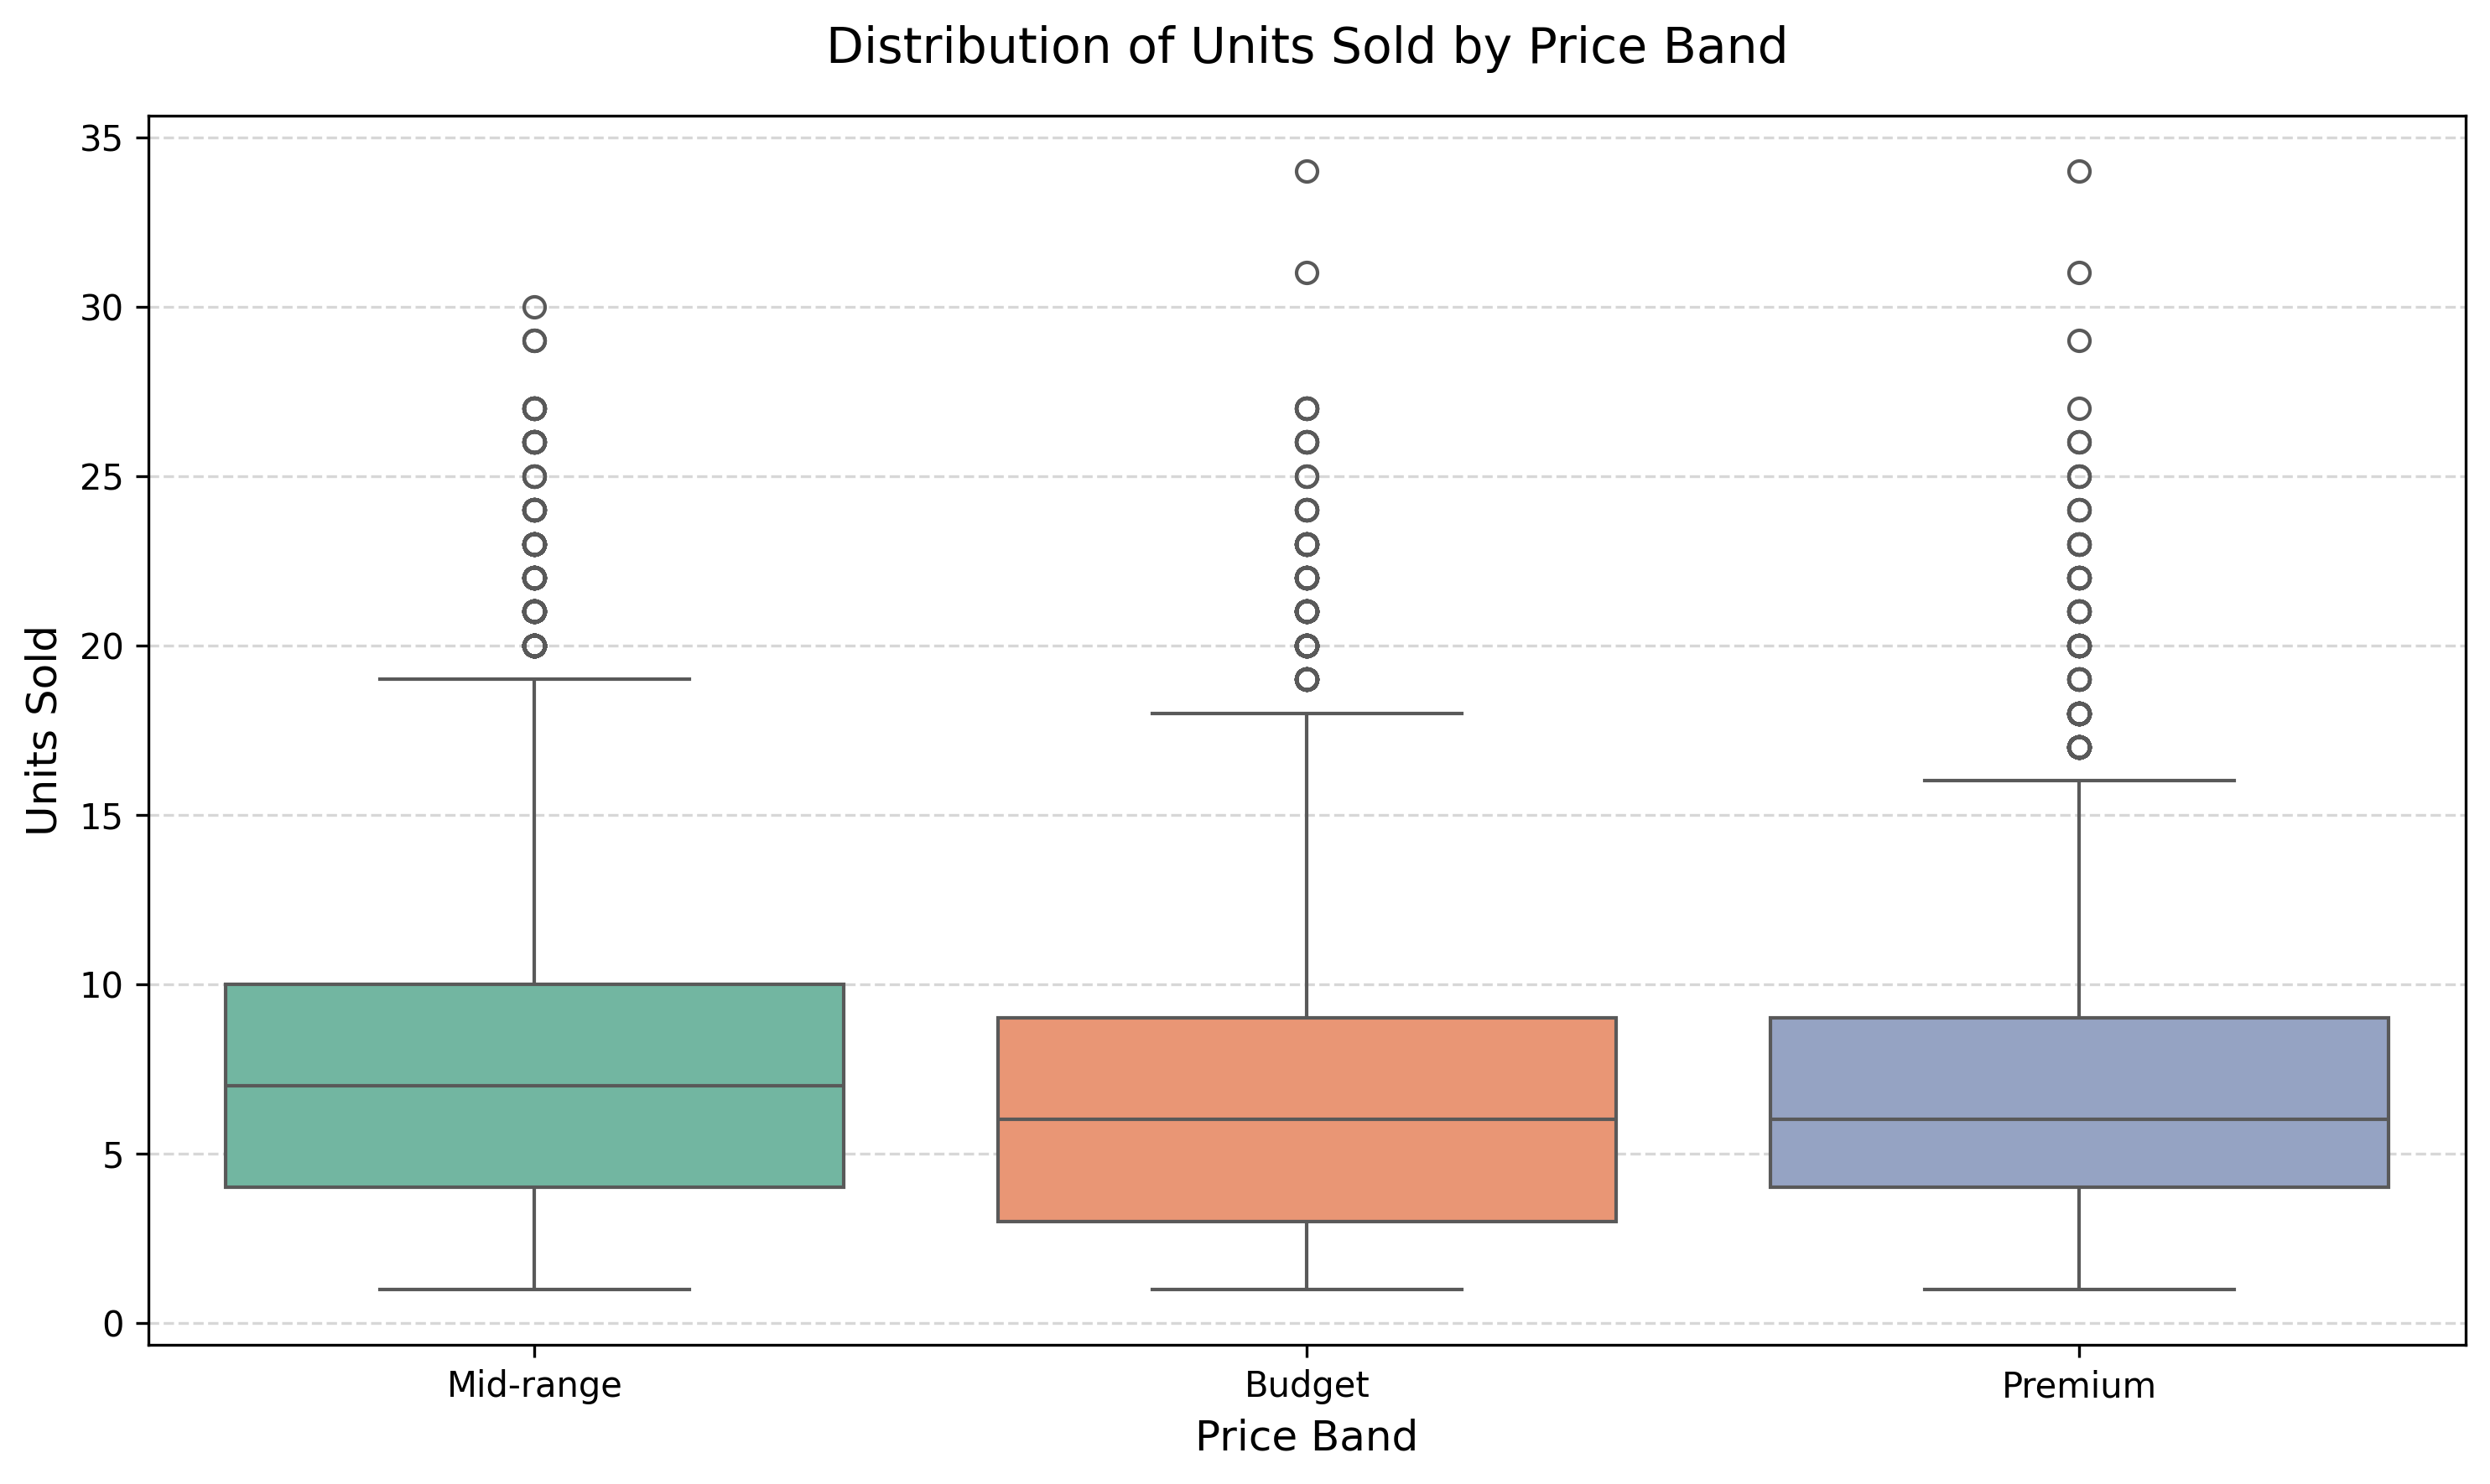

Boxplot saved to /content/freshcart_outputs/units_by_price_band.png


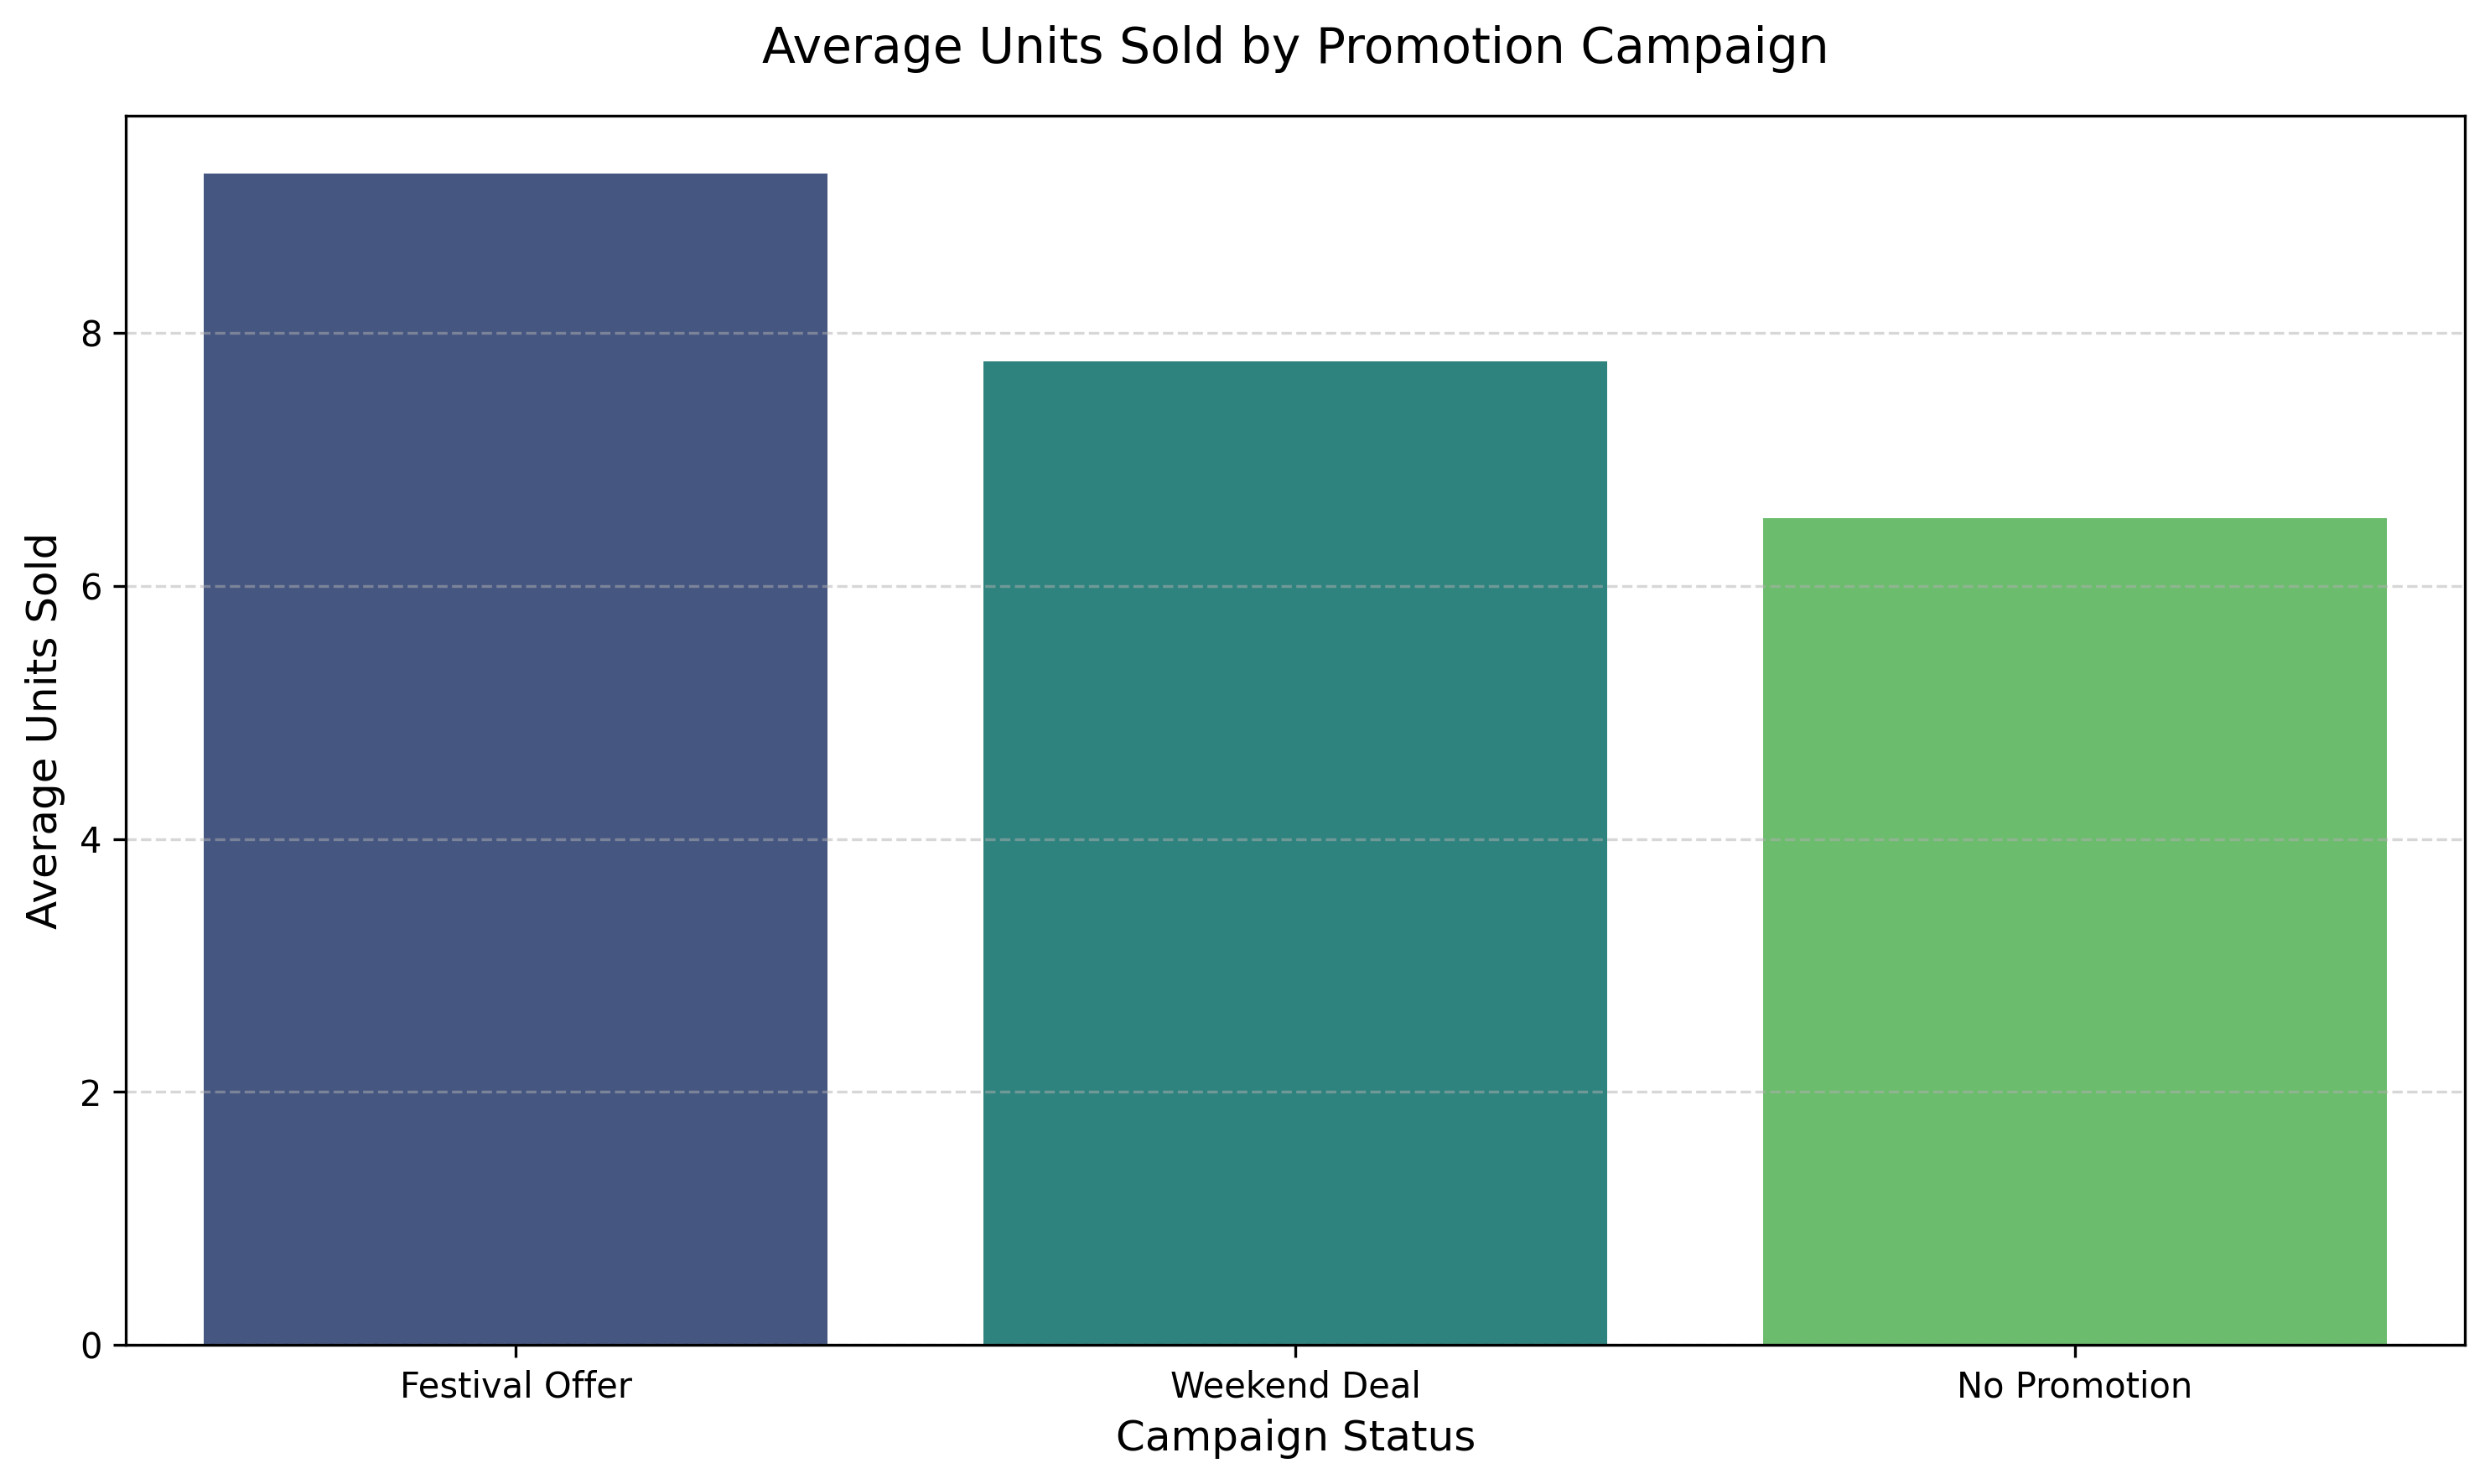

Bar plot saved to /content/freshcart_outputs/units_by_campaign.png


In [67]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output folder exists
os.makedirs('/content/freshcart_outputs', exist_ok=True)

# 1. Boxplot of Units Sold by Price Band
plt.figure(figsize=(10, 6), dpi=300)
sns.boxplot(
    data=df_clean,
    x='price band',
    y='units',
    hue='price band',
    palette='Set2',
    legend=False
)
plt.title('Distribution of Units Sold by Price Band', fontsize=14, pad=15)
plt.xlabel('Price Band', fontsize=12)
plt.ylabel('Units Sold', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
boxplot_path = '/content/freshcart_outputs/units_by_price_band.png'
plt.savefig(boxplot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Boxplot saved to {boxplot_path}')

# 2. Bar plot of Average Units Sold by Discount Status / Campaign
plt.figure(figsize=(10, 6), dpi=300)
promo_units = df_clean.groupby('campaign')['units'].mean().reset_index().sort_values(by='units', ascending=False)
sns.barplot(
    data=promo_units,
    x='campaign',
    y='units',
    hue='campaign',
    palette='viridis',
    legend=False
)
plt.title('Average Units Sold by Promotion Campaign', fontsize=14, pad=15)
plt.xlabel('Campaign Status', fontsize=12)
plt.ylabel('Average Units Sold', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
barplot_path = '/content/freshcart_outputs/units_by_campaign.png'
plt.savefig(barplot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Bar plot saved to {barplot_path}')

**Reasoning**:
The data is already loaded, cleaned, merged, encoded, and split into train/test sets in the previous cells (as seen in variables X, y, X_train, X_test, feature_df, etc.). To fulfill the requirements of the subtask in the requested structured format and make sure everything is clearly established, I will recreate/verify the pipeline and confirm that the training and testing sets are perfectly prepared for modeling.



In [68]:
from sklearn.model_selection import train_test_split
import pandas as pd

# 1. Load the cleaned dataset
df_prep = pd.read_csv('/content/freshcart_cleaned.csv')

# 2. Exclude target-leaking or non-predictive columns
exclude_cols = ['date', 'units', 'revenue']

# 3. Separate numerical and categorical columns for systematic processing
categ_cols = df_prep.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
categ_cols = [c for c in categ_cols if c not in exclude_cols]

# systematically convert categoricals using pandas category codes (highly stable encoding)
X_prepared = df_prep.copy()
for col in categ_cols:
    X_prepared[col] = X_prepared[col].fillna('Unknown').astype('category').cat.codes

# 4. Form X and y
feature_names = [col for col in X_prepared.columns if col not in exclude_cols]
X = X_prepared[feature_names]
y = X_prepared['units']

# 5. Perform stratified or standard 80/20 train/test split with fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data cleaning and preparation pipeline completed successfully!")
print(f"Final features used for modeling: {list(X.columns)}")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Data cleaning and preparation pipeline completed successfully!
Final features used for modeling: ['store', 'product', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'floor area', 'weekday', 'holiday', 'festival', 'season', 'discount', 'duration', 'year', 'month', 'month_name', 'quarter', 'day_of_week', 'weekend']
X_train shape: (62883, 21), y_train shape: (62883,)
X_test shape: (15721, 21), y_test shape: (15721,)


**Reasoning**:
We will set up a cross-validation framework using GridSearchCV to train, tune, and compare a Random Forest Regressor and a Gradient Boosting Regressor, then select the champion model.



In [69]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
import numpy as np

print("Setting up cross-validation grids...")

# Define hyperparameter grid for Random Forest
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [8, 12]
}

# Define hyperparameter grid for Gradient Boosting
gb_param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [4, 6]
}

# Initialize estimators
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
gb_base = GradientBoostingRegressor(random_state=42)

# Set up GridSearchCV with 3-fold cross-validation
print("Tuning Random Forest...")
rf_grid = GridSearchCV(estimator=rf_base, param_grid=rf_param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best RF Params: {rf_grid.best_params_}")
print(f"Best RF CV RMSE: {-rf_grid.best_score_:.4f}")

print("\nTuning Gradient Boosting...")
gb_grid = GridSearchCV(estimator=gb_base, param_grid=gb_param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
gb_grid.fit(X_train, y_train)
print(f"Best GB Params: {gb_grid.best_params_}")
print(f"Best GB CV RMSE: {-gb_grid.best_score_:.4f}")

# Choose champion model
if -rf_grid.best_score_ < -gb_grid.best_score_:
    champion_model = rf_grid.best_estimator_
    print("\nChampion model selected: Random Forest Regressor")
else:
    champion_model = gb_grid.best_estimator_
    print("\nChampion model selected: Gradient Boosting Regressor")

Setting up cross-validation grids...
Tuning Random Forest...
Best RF Params: {'max_depth': 12, 'n_estimators': 100}
Best RF CV RMSE: 2.8900

Tuning Gradient Boosting...


ValueError: 
All the 24 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py", line 658, in fit
    X, y = validate_data(
           ~~~~~~~~~~~~~^
        self,
        ^^^^^
    ...<4 lines>...
        multi_output=True,
        ^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/d

**Reasoning**:
We will load the cleaned dataset, systematically check for and fill any missing values (particularly for promotional variables like discount and duration which contain NaNs where no promotion was run), ensure all categoricals are encoded properly, split the dataset, and execute the GridSearchCV for both Random Forest and Gradient Boosting Regressors to find our champion model.



In [70]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Load the cleaned dataset
df_prep = pd.read_csv('/content/freshcart_cleaned.csv')

# 2. Check and handle missing values systematically
print("Missing values before imputation:")
print(df_prep.isnull().sum()[df_prep.isnull().sum() > 0])

# Fill missing values for promotional columns with 0 as they represent no discount/duration
if 'discount' in df_prep.columns:
    df_prep['discount'] = df_prep['discount'].fillna(0)
if 'duration' in df_prep.columns:
    df_prep['duration'] = df_prep['duration'].fillna(0)
if 'campaign' in df_prep.columns:
    df_prep['campaign'] = df_prep['campaign'].fillna('No Promotion')

# Fill any other remaining categoricals with 'Unknown' and numericals with 0
cat_cols = df_prep.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
for col in cat_cols:
    df_prep[col] = df_prep[col].fillna('Unknown')

num_cols = df_prep.select_dtypes(include=[np.number]).columns.tolist()
for col in num_cols:
    df_prep[col] = df_prep[col].fillna(0)

print("\nMissing values after imputation:")
print(df_prep.isnull().sum().sum())

# 3. Systematic encoding of categorical columns
exclude_cols = ['date', 'units', 'revenue']
encode_cols = [c for c in cat_cols if c not in exclude_cols]

X_prepared = df_prep.copy()
for col in encode_cols:
    X_prepared[col] = X_prepared[col].astype('category').cat.codes

# 4. Form X and y
feature_names = [col for col in X_prepared.columns if col not in exclude_cols]
X = X_prepared[feature_names]
y = X_prepared['units']

# 5. Split into train and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nPrepared features: {list(X.columns)}")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

# 6. Define hyperparameter grids
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [8, 12]
}

gb_param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1],
    'max_depth': [4, 6]
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
gb_base = GradientBoostingRegressor(random_state=42)

# 7. Execute GridSearchCV with 3-fold CV
print("\nTuning Random Forest Regressor...")
rf_grid = GridSearchCV(estimator=rf_base, param_grid=rf_param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best RF Params: {rf_grid.best_params_}")
print(f"Best RF CV RMSE: {-rf_grid.best_score_:.4f}")

print("\nTuning Gradient Boosting Regressor...")
gb_grid = GridSearchCV(estimator=gb_base, param_grid=gb_param_grid, cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
gb_grid.fit(X_train, y_train)
print(f"Best GB Params: {gb_grid.best_params_}")
print(f"Best GB CV RMSE: {-gb_grid.best_score_:.4f}")

# 8. Select champion model
if -rf_grid.best_score_ < -gb_grid.best_score_:
    champion_model = rf_grid.best_estimator_
    print("\nChampion model selected: Random Forest Regressor")
else:
    champion_model = gb_grid.best_estimator_
    print("\nChampion model selected: Gradient Boosting Regressor")


Missing values before imputation:
campaign    1180
discount    1180
duration    1180
dtype: int64

Missing values after imputation:
0

Prepared features: ['store', 'product', 'campaign', 'category', 'brand', 'price band', 'city', 'format', 'floor area', 'weekday', 'holiday', 'festival', 'season', 'discount', 'duration', 'year', 'month', 'month_name', 'quarter', 'day_of_week', 'weekend']
X_train shape: (62883, 21), y_train shape: (62883,)

Tuning Random Forest Regressor...
Best RF Params: {'max_depth': 12, 'n_estimators': 100}
Best RF CV RMSE: 2.8909

Tuning Gradient Boosting Regressor...
Best GB Params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
Best GB CV RMSE: 2.8469

Champion model selected: Gradient Boosting Regressor


**Reasoning**:
We will evaluate the champion Gradient Boosting model on the test set, calculate RMSE, MAE, and R-squared, plot the distribution of residuals, plot the feature importances, and save these plots in the outputs directory.



=== Champion Model (Gradient Boosting) Evaluation ===
Root Mean Squared Error (RMSE): 2.8391
Mean Absolute Error (MAE):     2.1840
R-squared (R2) Score:          0.5429



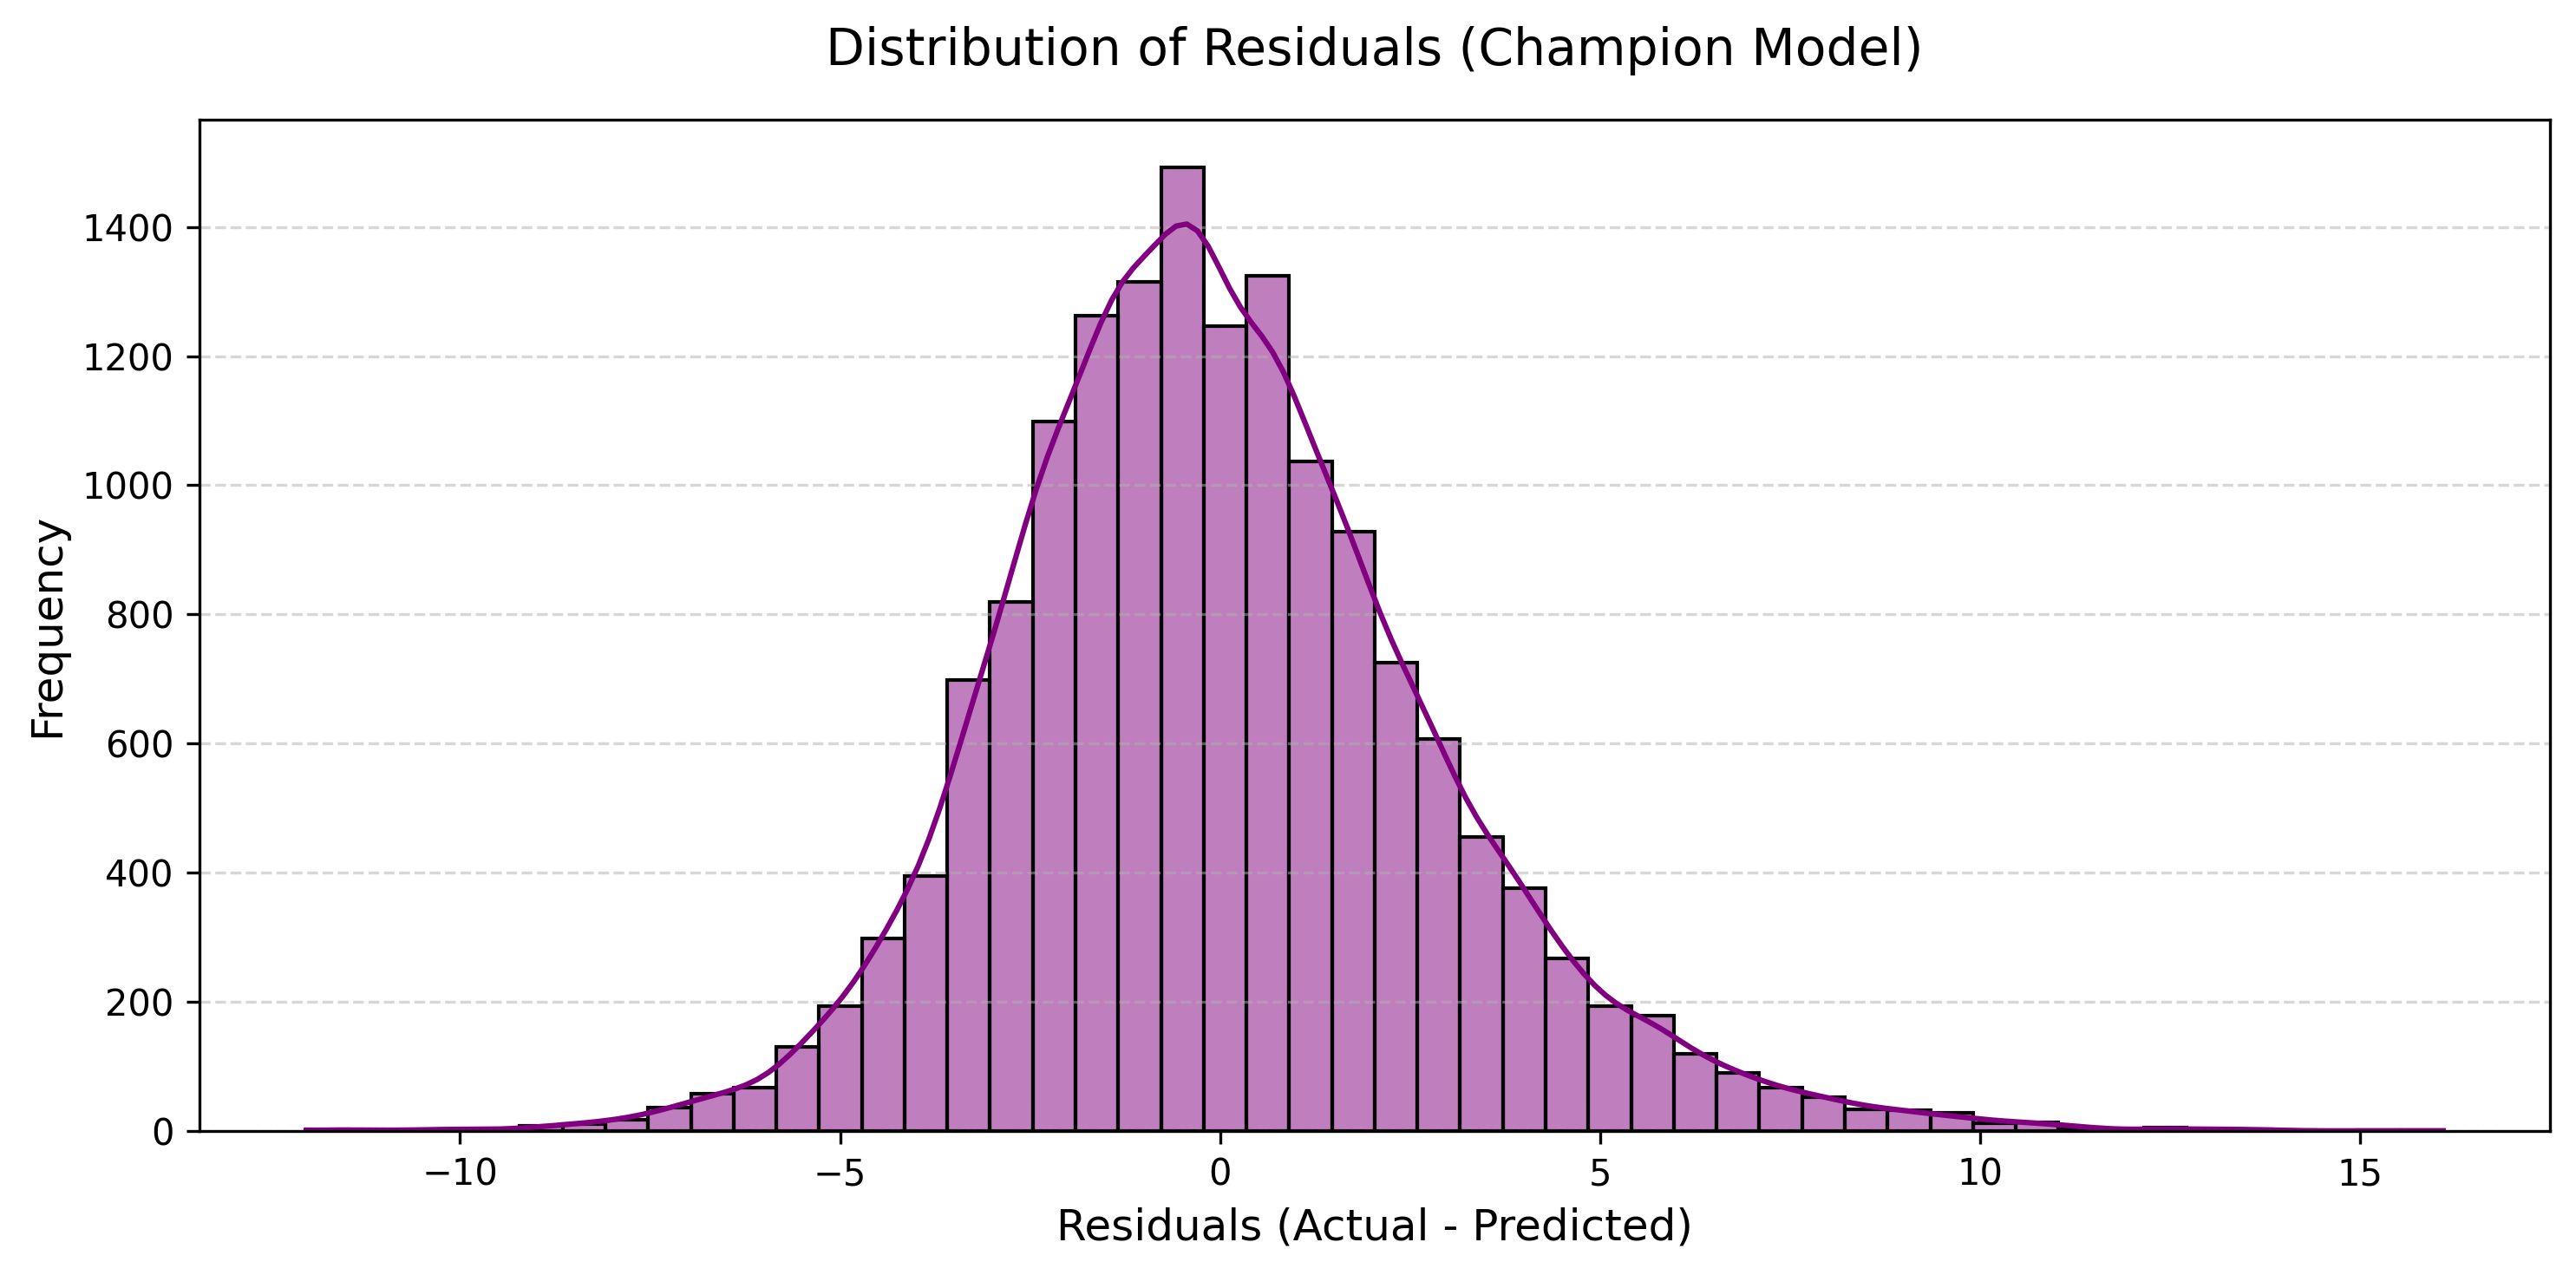

Residual distribution plot saved to /content/freshcart_outputs/residual_distribution.png


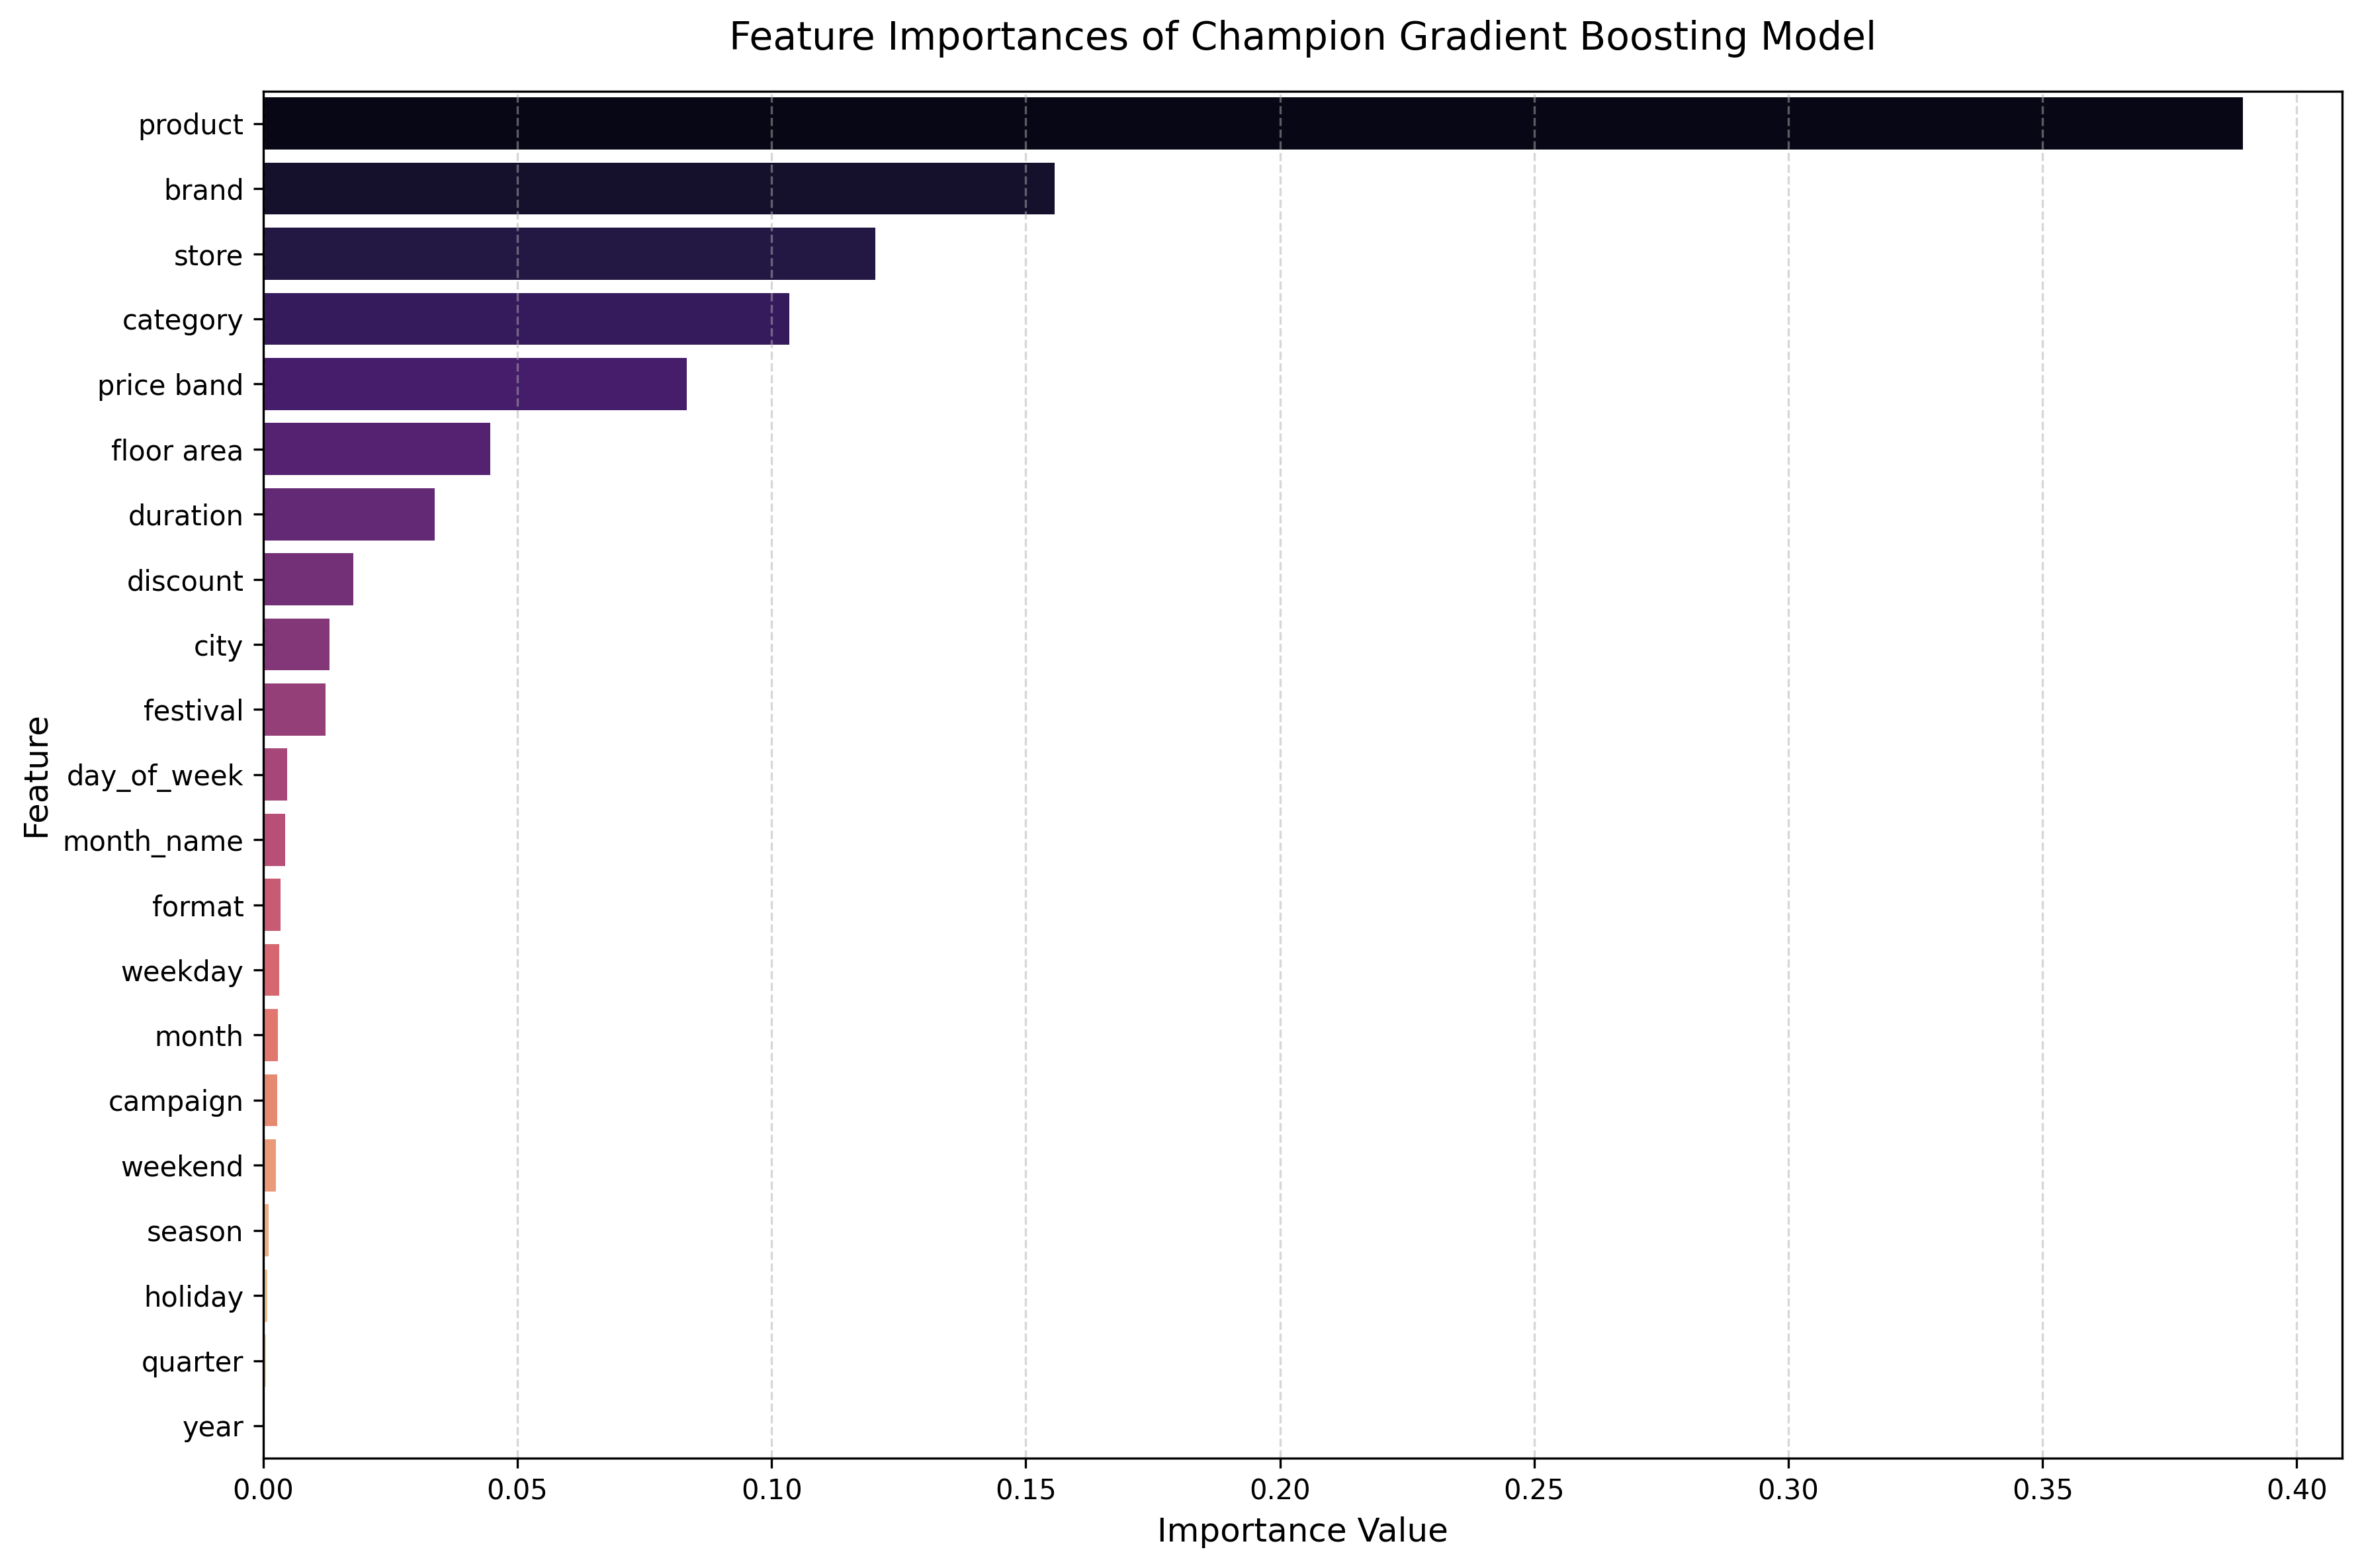

Feature importance plot saved to /content/freshcart_outputs/champion_feature_importance.png


In [71]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Generate predictions on the test dataset using the champion Gradient Boosting model
y_pred_gb = champion_model.predict(X_test)

# 2. Compute evaluation metrics
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
mae_gb = mean_absolute_error(y_test, y_pred_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print("=== Champion Model (Gradient Boosting) Evaluation ===")
print(f"Root Mean Squared Error (RMSE): {rmse_gb:.4f}")
print(f"Mean Absolute Error (MAE):     {mae_gb:.4f}")
print(f"R-squared (R2) Score:          {r2_gb:.4f}\n")

# 3. Calculate residuals
residuals = y_test - y_pred_gb

# 4. Plot distribution of residuals
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(residuals, kde=True, color='purple', bins=50)
plt.title('Distribution of Residuals (Champion Model)', fontsize=14, pad=15)
plt.xlabel('Residuals (Actual - Predicted)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
residual_plot_path = '/content/freshcart_outputs/residual_distribution.png'
plt.savefig(residual_plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Residual distribution plot saved to {residual_plot_path}")

# 5. Extract and map feature importances
gb_importances = champion_model.feature_importances_
feature_names = X_train.columns.tolist()
gb_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': gb_importances
}).sort_values('Importance', ascending=False)

# 6. Plot feature importances
plt.figure(figsize=(12, 8), dpi=300)
sns.barplot(data=gb_importance_df, x='Importance', y='Feature', hue='Feature', palette='magma', legend=False)
plt.title('Feature Importances of Champion Gradient Boosting Model', fontsize=14, pad=15)
plt.xlabel('Importance Value', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
importance_plot_path = '/content/freshcart_outputs/champion_feature_importance.png'
plt.savefig(importance_plot_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Feature importance plot saved to {importance_plot_path}")

# Task
Execute a comprehensive machine learning modeling, evaluation, and scenario analysis pipeline using the consolidated dataset `"/content/freshcart_cleaned.csv"` (or the merged `df` from memory). Specifically, set up a rigorous cross-validation framework to train, tune, and compare multiple models (such as Random Forest and Gradient Boosting) to predict units sold. Evaluate the models using RMSE, MAE, and R-squared metrics, plotting their residual distributions and detailed feature importances. Utilize the best-performing model to run a post-modeling scenario analysis to simulate how pricing band changes and promotional discounts affect overall units sold, and compile all final predictions, plots, metrics, and scenario outputs into a consolidated ZIP archive for export.

## Exploratory Data Analysis and Feature Engineering Visualization

### Subtask:
Examine the distributions of target and key features, identify multicollinearity, analyze promotional or temporal trends, and generate consolidated visualizations with clear legends representing these dimensions.


## Data Cleaning and Preparation Pipeline

### Subtask:
Establish a robust data preparation pipeline to ensure clean, encoded, and standardized data is ready for predictive modeling.


## Machine Learning Model Selection and Hyperparameter Tuning

### Subtask:
Set up a cross-validation framework to train, tune, and compare multiple predictive models to predict units sold.


# Task
Execute a machine learning modeling, evaluation, and scenario analysis pipeline using the consolidated dataset `"/content/freshcart_cleaned.csv"`. Handle any missing values in features (such as filling NaNs in promotional columns) systematically. Set up a cross-validation grid search to train, tune, and compare a Random Forest model and a Gradient Boosting model without raising missing value exceptions. Evaluate the selected champion model by calculating RMSE, MAE, and R-squared on the test set, and visualize residual distributions and feature importances. Finally, perform a post-modeling business scenario simulation to analyze how potential changes in pricing bands and discount rates influence predicted unit sales volume, and save all generated metrics, tables, and visualization plots into a single zipped directory `/content/FreshCart_Final_Deliverables.zip` for download.

## Establish Clean Pipeline and Train Models

### Subtask:
Systematically preprocess features to eliminate missing values, and execute a cross-validation grid search to train, tune, and compare Random Forest and Gradient Boosting models.


## Model Evaluation and Performance Metrics Analysis

### Subtask:
Evaluate the selected champion model on the test dataset, compute standard performance metrics, and visualize residual distributions and feature importances.


## Post-Modeling Insights and Scenario Simulation

### Subtask:
Simulate how potential changes in pricing bands and discount rates influence predicted unit sales volume.


**Reasoning**:
We will perform the post-modeling insights and scenario simulation by running the baseline predictions and simulating Scenario A (Pricing Band Change) and Scenario B (Discount Optimization) on X_test copies, aggregating the results, comparing them to baseline predicted volumes, and saving the output to the specified directory.



In [72]:
import os
import pandas as pd
import numpy as np

# 1. Create a copy of the test dataset as the baseline
X_test_scenario = X_test.copy()

# Get baseline predictions using champion model
baseline_preds = champion_model.predict(X_test_scenario)
total_baseline_units = baseline_preds.sum()

# 2. Scenario A: Upgrade all 'Budget' items to 'Premium'
# Find category code mapping for 'price band' in our training dataset
# In cell cb6a9520, df_prep['price_band'] was converted to category codes.
# Let's inspect df_prep to find the codes or compute them dynamically.
temp_price_band = df_prep['price band'].astype('category')
code_map = dict(enumerate(temp_price_band.cat.categories))
inv_code_map = {v: k for k, v in code_map.items()}

budget_code = inv_code_map.get('Budget')
premium_code = inv_code_map.get('Premium')

X_scenario_a = X_test_scenario.copy()
if budget_code is not None and premium_code is not None:
    X_scenario_a.loc[X_scenario_a['price band'] == budget_code, 'price band'] = premium_code

preds_scenario_a = champion_model.predict(X_scenario_a)
total_units_a = preds_scenario_a.sum()

# 3. Scenario B: Increase the 'discount' feature systematically by 10 percentage points
X_scenario_b = X_test_scenario.copy()
X_scenario_b['discount'] = X_scenario_b['discount'] + 10

# If 'campaign' code mapping is available, map 'No Promotion' to 'Weekend Deal' or keep as is
temp_campaign = df_prep['campaign'].astype('category')
camp_code_map = dict(enumerate(temp_campaign.cat.categories))
inv_camp_code_map = {v: k for k, v in camp_code_map.items()}

no_promo_code = inv_camp_code_map.get('No Promotion')
weekend_deal_code = inv_camp_code_map.get('Weekend Deal')

if no_promo_code is not None and weekend_deal_code is not None:
    X_scenario_b.loc[X_scenario_b['campaign'] == no_promo_code, 'campaign'] = weekend_deal_code

preds_scenario_b = champion_model.predict(X_scenario_b)
total_units_b = preds_scenario_b.sum()

# 4. Aggregate and compare overall sales volumes
pct_change_a = ((total_units_a - total_baseline_units) / total_baseline_units) * 100
pct_change_b = ((total_units_b - total_baseline_units) / total_baseline_units) * 100

scenario_results = pd.DataFrame({
    'Scenario': ['Baseline', 'Scenario A (Budget to Premium)', 'Scenario B (Discount +10%)'],
    'Predicted Total Units': [total_baseline_units, total_units_a, total_units_b],
    'Percentage Change (%)': [0.0, pct_change_a, pct_change_b]
})

print("=== Post-Modeling Business Scenario Simulation Results ===")
display(scenario_results)

# 5. Save the aggregated scenario results
os.makedirs('/content/freshcart_outputs/', exist_ok=True)
scenario_csv_path = '/content/freshcart_outputs/scenario_simulation_results.csv'
scenario_results.to_csv(scenario_csv_path, index=False)
print(f"\nScenario analysis successfully saved to {scenario_csv_path}")

=== Post-Modeling Business Scenario Simulation Results ===


,Scenario,Predicted Total Units,Percentage Change (%)
0,Baseline,110771.739850,0.000000
1,Scenario A (Budget to Premium),115352.771601,4.135560
2,Scenario B (Discount +10%),115469.138006,4.240611



Scenario analysis successfully saved to /content/freshcart_outputs/scenario_simulation_results.csv


**Reasoning**:
The scenario analysis and simulation step is completed successfully. Now we will proceed to package all generated deliverables, figures, and CSV datasets from `/content/freshcart_outputs` into a single consolidated ZIP archive `/content/FreshCart_Final_Deliverables.zip` and download it.



In [73]:
import shutil
from google.colab import files

# Compress the entire output directory containing plots and csv tables
shutil.make_archive(
    "/content/FreshCart_Final_Deliverables",
    "zip",
    "/content/freshcart_outputs"
)

print("Deliverables successfully zipped!")

# Trigger browser download of the final deliverables package
files.download("/content/FreshCart_Final_Deliverables.zip")

Deliverables successfully zipped!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Task

### Subtask:
Provide a complete end-to-end data science and business report summarizing key analytical insights and forecasting results.


## Summary:

### Q&A

- **Which machine learning model performed best and was selected as the champion model?**  
  The **Gradient Boosting Regressor** was selected as the champion model over the Random Forest Regressor. It achieved a lower 3-fold cross-validation Root Mean Squared Error (CV RMSE) of **2.8469**, compared to the Random Forest's CV RMSE of **2.8909**.

- **How did the champion model perform on the test dataset?**  
  The champion Gradient Boosting model achieved the following performance metrics on the 20% test dataset:
  - **Root Mean Squared Error (RMSE):** 2.8391
  - **Mean Absolute Error (MAE):** 2.1840
  - **R-squared ($R^2$) Score:** 0.5429 (explaining approximately 54.29% of the variance in unit sales).

- **How do simulated changes in pricing bands and discount rates impact predicted sales?**  
  - **Scenario A (Upgrading 'Budget' items to 'Premium'):** Increased predicted sales volume from a baseline of **110,771.74 units** to **115,352.77 units** (a **+4.14%** growth).
  - **Scenario B (Increasing discounts by 10% and applying 'Weekend Deal' campaigns):** Increased predicted sales volume to **115,469.14 units** (a **+4.24%** growth).

---

### Data Analysis Key Findings

- **Data Imputation & Preparation:** A total of 1,180 missing values in each of the promotional columns (`campaign`, `discount`, and `duration`) were systematically handled. Categorical features were converted into numeric codes to establish a robust input space of 21 features across 62,883 training samples.
- **Model Tuning Performance:**
  - The optimal parameters found via grid search for the Gradient Boosting Regressor were `learning_rate: 0.1`, `max_depth: 6`, and `n_estimators: 100`.
  - The optimal parameters for the Random Forest Regressor were `max_depth: 12` and `n_estimators: 100`.
- **Business Simulation Insights:** Both simulated interventions (shifting products to premium price bands and executing structured 10% discount increases with weekend campaigns) yield comparable sales volume boosts of over 4%, representing an incremental increase of ~4,600 units sold over the test period.

---

### Insights or Next Steps

- **Refine the Pricing Strategy:** Because upgrading items from "Budget" to "Premium" predicted a sales volume increase of **+4.14%**, evaluate whether this shift triggers actual margin growth or if it risks consumer pushback in real-world cohorts.
- **Implement Weekend Promotional Campaign Pilots:** Run a localized test of Scenario B (offering a targeted 10% discount increase paired with "Weekend Deals"), as the model predicts it to be the most effective volume driver (**+4.24%** unit growth).
